# Explication du projet

L'entreprise place de marché est une société anglophone spécialisée dans la vente de produits en ligne. Elle met en relation des vendeurs proposant des articles à la vente et des acheteurs répartis dans différents pays.
Actuellement, la catégorisation des produits disponibles sur la plateforme est effectuée manuellement par les vendeurs. Ce processus, peut donc être sujet à des erreurs de saisie ou de subjectivité. Dans ce contexte, l’entreprise place de marché souhaite automatiser l’attribution des catégories produits afin d’optimiser ses processus et d’améliorer la qualité de la classification. Elle nous sollicite pour évaluer la faisabilité d’un système de classification automatique des produits, basé sur deux types de données fournies par les vendeurs:

- Les descriptions textuelles des produits en anglais
- Les images associées aux produits

Les deux précédents notebooks ont permis d'étudier la faisabilité d'une classification automatiques des produits à partir des descriptions et des images. Ici, la phase de classification automatique va être mise en place à partir des images. Pour cela on va utiliser le modèle VGG16 déjà exploré lors de la partie précédente en testant différentes approches.

# Sommaire
- [1 Explication du projet](#Explication-du-projet)
- [2 Sommaire](#Sommaire)
- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Création du modèle et présentation des étapes communes aux différentes approches](#Création-du-modèle-et-présentation-des-étapes-communes-aux-différentes-approches)
- [5 Approche 1: Préparation initiale des images avec le modèle VGG16](#Approche-1:-Préparation-initiale-des-images)
- [6 Approche 2: Data augmentation avec ImageDatagenerator et le modèle VGG16](#Approche-2:-Data-augmentation-avec-ImageDatagenerator)
- [7 Approche 3: Approche par Dataset sans data augmentation avec le modèle VGG16](#Approche-3:-Approche-par-Dataset-sans-data-augmentation
)
- [8 Approche 4: Approche par Dataset avec data augmentation intégrée au modèle VGG16](#Approche-4:-Approche-par-Dataset-avec-data-augmentation-intégrée-au-modèle)
- [9 Comparaison des différentes approches](#Comparaison-des-différentes-approches)
- [10 Approche 5: Approche par Dataset avec data augmentation intégrée au modèle MobileNet](#Approche-5:-Approche-par-Dataset-avec-data-augmentation-intégrée-au-modèle-avec-MobileNet)
- [11 Conclusions](#Conclusions)

# Import des bibliothèques et des données

**Bibliothèques**

In [1]:
# Manipulation de données
import pandas as pd
import numpy as np
from collections import Counter

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from plot_keras_history import show_history, plot_history
from plotnine import *

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

# Traitement d'image
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Deep learning 
import tensorflow as tf
from tensorflow.keras.preprocessing.image import array_to_img
from tensorflow.keras import Input
from tensorflow.keras.models import Model, Sequential, load_model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    Rescaling,
    RandomFlip,
    RandomRotation,
    RandomZoom
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import applications

# Autres 
import warnings
import time
import os
import random
import shutil

In [2]:
# Désactivation du warning liée à la décompression de l'image anormalement grande
warnings.simplefilter('ignore', Image.DecompressionBombWarning)

**Données**

In [3]:
# Import du jeu de données 
Data_image = pd.read_csv("../Output/Table/Data_image.csv", index_col=0)

# Création du modèle et présentation des étapes communes aux différentes approches

Avant de démarrer la phase de classification automatique des images. Une fonction permettant de créer le modèle qui sera utilisé va être définie. Comme mentionné dans l'introduction, on va partir sur le modèle VGG16 préentrainé sur ImageNet et l'adapter pour notre problème de classification automatique des images. 

Pour cela, la couche de classification originelle du modèle sera tout d'abord retirée du modèle. Les couches convolutionnelles seront gelées de manière à conserver les caractéristiques visuelles déjà apprises lors du préentrainement du modèle. Enfin de nouvelles couches seront ajoutées pour adapter le modèle à la nouvelle tache de classification, comprenant une couche de pooling, une couche dense avec une activation de type Relu et pour finir une deuxieme couche dense avec une activation de type softmax correspondant à la couche de sortie fournissant en sortie les probabilité des 7 classes de catégorie de nos produits. Une étape de dropout sera inséré entre les deux couches denses pour désactiver 50% des neurones dans le but de réduire le surapprentissage. 

La fonction de cout utilisée sera la categorical cross entropie qui mesure l'écart entre les probabilités prédites et les vraies classes afin de guider l'apprentissage du modèle pendant l'entrainement. Concernant la métrique d'évaluation de performance; celle qui sera définie correspond à l'accuracy qui mesure la proportion de prédictions correctes sur l'ensemble des prédictions réalisées. Pour que cette mesure soit fiable et représentative de la performance réelle du modèle, il faudra s'assurer que les classes sont globalement équilibrées dans les différents sous ensembles de données.

In [4]:
def create_model_fct() :
    
    """
    Crée et compile un modèle de classification d'images basé sur VGG16 pré-entraîné.

    Le modèle utilise VGG16 comme extracteur de caractéristiques (sans la couche de classification finale),
    gèle toutes ses couches pour empêcher leur mise à jour durant l'entraînement, puis ajoute un bloc de 
    classification personnalisée composée de :
    - une couche de pooling global (GlobalAveragePooling2D),
    - une couche dense de 256 neurones avec activation ReLU,
    - une couche Dropout (0.5) pour limiter le surapprentissage,
    - une couche de sortie dense avec 7 neurones (softmax) pour la classification multi-classes.

    Le modèle est compilé avec l'optimiseur RMSprop, la fonction de perte categorical_crossentropy, et la métrique d'évaluation accuracy.

    Sortie:
        model (keras.Model): Le modèle Keras compilé prêt à être entraîné.
    """
    
    # Chargement du modèle pré-entraîné
    model0 = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))

    # Gel des couches convolutionnelles (toutes les couches de VGG16 sont mises en non entrainable)
    for layer in model0.layers:
        layer.trainable = False

    # Exctraction de la sortie du réseau
    x = model0.output
    
    # Ajout d'une couche de pooling 
    x = GlobalAveragePooling2D()(x)
    
    # Ajout d'une couche dense
    x = Dense(256, activation='relu')(x)
    
    # Désactivation aléatoire de 50% des neurones pour éviter l'overfitting
    x = Dropout(0.5)(x)
    
    # Ajout de la couche de sortie
    predictions = Dense(7, activation='softmax')(x)

    # Définition du nouveau modèle 
    model = Model(inputs=model0.input, outputs=predictions)
    
    # Compilation du modèle 
    model.compile(loss="categorical_crossentropy", optimizer='rmsprop', metrics=["accuracy"])

    # Affichage de l'architecture du modèle
    print(model.summary())
    
    return model
    

Les catégories associées aux différentes images seront encodées à l’aide d’un LabelEncoder, ce qui permettra de convertir les étiquettes textuelles en valeurs numériques utilisables par les algorithmes de machine learning. Cette méthode offre également la possibilité de retrouver facilement les catégories d’origine ce qui sera utile lors de l’interprétation et de la présentation des résultats.

In [5]:
# Initialisation d'un label encoder
encoder = LabelEncoder()

# Encodage de la variable correspondant aux catégories
Data_image['label'] = encoder.fit_transform(Data_image['First_category']) 

Il sera également important de rendre les résulats obtenus par les modèle de deep learning reproductibles. Pour cela, une autre fonction sera définie et permettra notamment de synchroniser le générateur de nombre aléatoire de tensorflow de manière a fixer la part de l'aléatoire de toutes les sources utilisées par Keras.

In [6]:
def set_seed(seed=42):
    """
    Fixe la part de l'aléatoire pour assurer la reproductibilité des résultats.

    Cette fonction synchronise les générateurs de nombres aléatoires utilisés 
    par Python, NumPy et TensorFlow, et active les options de déterminisme 
    dans TensorFlow pour garantir que les exécutions successives produisent 
    les mêmes résultats.

    Paramètres
        seed (int, optionnel): valeur de seed à utiliser
    """
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    np.random.seed(seed)
    random.seed(seed)

In [7]:
# Appel de la fonction
set_seed(42)

Pour chacune des approches qui seront présentées, les données seront systématiquement divisées en trois ensembles : un jeu d'entraînement, un jeu de validation et un jeu de test. Cela permettra de pouvoir évaluer les performances du modèle de facon rigoureuse.

Des callbacks seront mis en place et sauvegardés de manière à conserver les informations générées à chaque étape de l'entraînement. Cela permettra d’analyser a posteriori l’évolution des performances du modèle, ainsi que les métriques associées à chaque phase du processus d'entrainement.

# Approche 1: Préparation initiale des images

L'approche qui sera utilisée en premier lieu consiste à charger et à préparer les images à l'avance avant de les injecter dans le modèle. Pour cela, on va utiliser une autre fonction qui permettra de charger les images, de les redimensionner à une taille standart et attendue par le modèle puis de les transformer en tableau de type array. L'utilisation de la fonction preprocess_input spécifique au modèle VGG16 permet d'ajouter d'autres prétraitements utilisés lors de l'entrainement de ce modèle. En sortie, la fonction renverra un tableau de forme (nombre de produits,  hauteur, largeur, nombre de cannaux) qui sera prêt à être utilisés comme entrée du modèle. 

In [8]:
def image_prep_fct(data) :
    
    """
    Prépare un ensemble d'images à partir de chemins d'accès, en les chargeant,
    redimensionnant, convertissant en tableaux NumPy et en appliquant un prétraitement.

    Paramètres
        data (pandas.DataFrame): DataFrame contenant au moins une colonne 'image_path' avec les chemins des images à charger.

    Sortie
        prepared_images_np (numpy.ndarray): Tableau NumPy de forme (n_images, 224, 224, 3), contenant les images prétraitées prêtes 
        à être utilisées comme entrée pour un modèle de deep learning.
    """
    
    # Initialisation d'une liste vide pour stocker les images
    prepared_images = []
    
    # Pour chaque chemin d'images dans data
    for image_num in range(len(data['image_path'])) :
        
        # Chargement de l'image et redimensionnement
        img = (load_img(
            data['image_path'][image_num],
            target_size=(224, 224)))
        
        # Conversion des images en array
        img = img_to_array(img)
        
        # Prétraitement spécifique à VGG16 de l'image 
        img = preprocess_input(img)
        
        # Ajout de l'image prétraitée dans la liste
        prepared_images.append(img)
     
    # Conversion de la liste en array
    prepared_images_np  = np.array(prepared_images)
        
    return prepared_images_np 
  
# Appel de la fonction
images = image_prep_fct(Data_image)

# Affichage de la forme de l'array
print(images.shape)

(1050, 224, 224, 3)


Afin de pouvoir analyser les performances du modèle de façon rigoureuse, les données vont donc être découpées en jeu de données d'entrainement, en jeu de données de validation et en jeu de données de test. Les données de test et de validation représenteront chacunes 20% de la totalité des données, tandis que les données d'entrainement représenteront 60% de la totalité du jeu de données. Le découpage sera effectué à l'aide d'une stratification sur la variable cible de façon à garantir une proportion équivalente de chaque catégorie dans les différents sous ensembles de données. La variable correspondant au label sera isolée et convertie en categorie.

In [9]:
# Définition du X pour la classification supervisée
X = images

# Définition du y pour la classification suprevisée
y = to_categorical(Data_image['label'])

# Vérification de la forme de y
print('format de la variable cible y :', y.shape)

# Découpage du jeu de données en train et test 
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Découpage du jeu de données train en train et validation 
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

# Vérification de l'équilibre des classes
print(Counter(np.argmax(y_train, axis=1)))
print(Counter(np.argmax(y_val, axis=1)))
print(Counter(np.argmax(y_test, axis=1)))

format de la variable cible y : (1050, 7)
Counter({6: 90, 1: 90, 3: 90, 0: 90, 4: 90, 2: 90, 5: 90})
Counter({0: 30, 2: 30, 6: 30, 4: 30, 1: 30, 5: 30, 3: 30})
Counter({6: 30, 5: 30, 2: 30, 0: 30, 3: 30, 1: 30, 4: 30})


Lors de l''entraînement d’un réseau de neurones les paramètres internes du modèles (les poids) sont ajustés afin de minimiser l’erreur entre les prédictions produites par le modèle et les valeurs cibles attendues. Ce processus se fait de manière itérative sur le jeu d'entraînement (X_train, y_train), en utilisant un algorithme d’optimisation comme la descente de gradient. Les données sont donc passées plusieurs fois à travers le modèles. Chaque passage correspond à un epoch. En général, plusieurs epoch sont nécessaires pour que le modèle apprenne des caractéristiques pertinentes à partir des données. Après chaque epoch, les performances du modèle sont évaluées sur un jeu de validation (X_val, y_val), afin de suivre sa progression sur des données qu’il n’a pas vues pendant l’entraînement proprement dit.

Deux callbacks seront utilisés lors de ce processus d’apprentissage :
- ModelCheckpoint : Ce callback sauvegarde automatiquement les poids du modèle lorsque la perte sur la validation (val_loss) atteint un minimum, ce qui permet de conserver le meilleur modèle atteint pendant l’entraînement, et non celui de la dernière epoch.
- EarlyStopping : Ce callback interrompt l'entraînement si val_loss ne s'améliore pas pendant un certain nombre d’époch consécutives (patience). Cela permet de prévenir le surapprentissage et de gagner du temps de calcul.

À l’issue de l’entraînement, les meilleurs poids enregistrés sont rechargés depuis le fichier sauvegardé. Les performances finales du modèle sont ensuite évaluées sur les jeux d'entrainement, de validation et de test, afin d’obtenir une estimation fiable de sa capacité à généraliser à de nouvelles données.

In [10]:
# Création du modèle
with tf.device('/gpu:0'): model1 = create_model_fct()

# Définition du chemin de sauvegarde
model1_save_path1 =  "../Models/CNN/VGG16/VGG16_1_best_weights.keras"

# Création d'un callback pour sauvegarder le modèle 
checkpoint = ModelCheckpoint(model1_save_path1, monitor='val_loss', verbose=1, save_best_only=True, mode='min')

# Définition d'un early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

# Liste des callbacks
callbacks_list = [checkpoint, es]

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,3

 Total params: 14,847,815 (56.64 MB)

 Trainable params: 133,127 (520.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

None


In [11]:
# Définition du temps avant l'entrainement du modèle
start_1 = time.time()

# Entraînement du modèle sur les données d'entraînement (X_train, y_train)
with tf.device('/gpu:0'): 
    history1 = model1.fit(X_train, y_train, epochs=50, batch_size=64, 
                       callbacks=callbacks_list, validation_data=(X_val, y_val), verbose=1)
    
# Calcul du temps d'execution de l'entrainement du modèle
duration_1 = time.time() - start_1

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.3022 - loss: 9.1092
Epoch 1: val_loss improved from inf to 1.46974, saving model to ../Models/CNN/VGG16_1_best_weights.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 92s 9s/step - accuracy: 0.3137 - loss: 8.8350 - val_accuracy: 0.7619 - val_loss: 1.4697
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6311 - loss: 2.5112
Epoch 2: val_loss improved from 1.46974 to 1.16944, saving model to ../Models/CNN/VGG16_1_best_weights.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 91s 9s/step - accuracy: 0.6326 - loss: 2.4902 - val_accuracy: 0.7714 - val_loss: 1.1694
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7266 - loss: 1.4764
Epoch 3: val_loss did not improve from 1.16944
10/10 ━━━━━━━━━━━━━━━━━━━━ 94s 10s/step - accuracy: 0.7276 - loss: 1.4682 - val_accuracy: 0.7619 - val_loss: 1.1705
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7673 - loss: 1.0568
Epoch 4: val_loss improved from 1.16944 to 1.05460, saving mo

In [12]:
# Calcul et afficahge des scores d'accuracy sur le dernier epoch
print("Score d'accuracy sur le dernier epoch")
print("---------------------------------------")
loss, accuracy = model1.evaluate(X_train, y_train, verbose=False, batch_size=64)
print("Training Accuracy:    {:.4f}".format(accuracy))
loss, accuracy = model1.evaluate(X_val, y_val, verbose=False, batch_size=64)
print("Validation Accuracy:  {:.4f}".format(accuracy))
loss, accuracy = model1.evaluate(X_test, y_test, verbose=False, batch_size=64)
print("Test Accuracy:        {:.4f}".format(accuracy))

Score d'accuracy sur le dernier epoch
---------------------------------------
Training Accuracy:    0.9968
Validation Accuracy:  0.8286
Test Accuracy:        0.8238


Au dernier epoch, le modèle atteint une accuracy très élevée sur les données d'entraînement (**99,68 %**), ce qui montre qu'il a bien appris à prédire les catégories des produits à partir des images sur cet ensemble. Cependant, on observe une baisse assez importante de la performance sur les données de validation (**82,86 %**) et sur le jeu de test (**82,38 %**). Cette différence de **17,4** suggère que le modèle commence à surapprendre les données d'entraînement, ce qui limite sa capacité à généraliser parfaitement sur des données nouvelles. On peut également effectuer cette analyse sur l'epoch où le jeu de validation a le plus minimiser la fonction cout.

In [13]:
# Chargement des poids de l'epoch optimal
model1=	load_model(model1_save_path1)

# Calcul et affichage des scores d'accuracy sur l'epoch optimal
print("Score d'accuracy sur l'epoch optimal")
print("---------------------------------------")
loss_train_1, accuracy_train_1 = model1.evaluate(X_train, y_train, verbose=False)
print("Train Accuracy:      {:.4f}".format(accuracy_train_1))
loss_val_1, accuracy_val_1 = model1.evaluate(X_val, y_val, verbose=False)
print("Validation Accuracy: {:.4f}".format(accuracy_val_1))
loss_test_1, accuracy_test_1 = model1.evaluate(X_test, y_test, verbose=False)
print("Test Accuracy:       {:.4f}".format(accuracy_test_1))

Score d'accuracy sur l'epoch optimal
---------------------------------------
Train Accuracy:      0.9794
Validation Accuracy: 0.8143
Test Accuracy:       0.8190


À l’epoch optimal, le modèle présente une accuracy de **97,94 %** sur l’ensemble d’entraînement, ce qui indique un bon apprentissage des données. L’accuracy sur l’ensemble de validation est de **81,43 %**, légèrement inférieure à celle du test (**81,90 %**). Malgré un score d'accuracy satisfaisant sur les données de validation, la différence (**16.5**) entre les scores d’entraînement et de validation suggère à nouveau que le modèle surapprend sur les données d'entrainement. 

Pour compléter cette analyse, il serait intéressant d'étudier la courbe d'apprentissage en suivant notamment l’évolution de l’accuracy et de la fonction de coût en fonction des epochs sur les jeux d’entraînement et de validation.

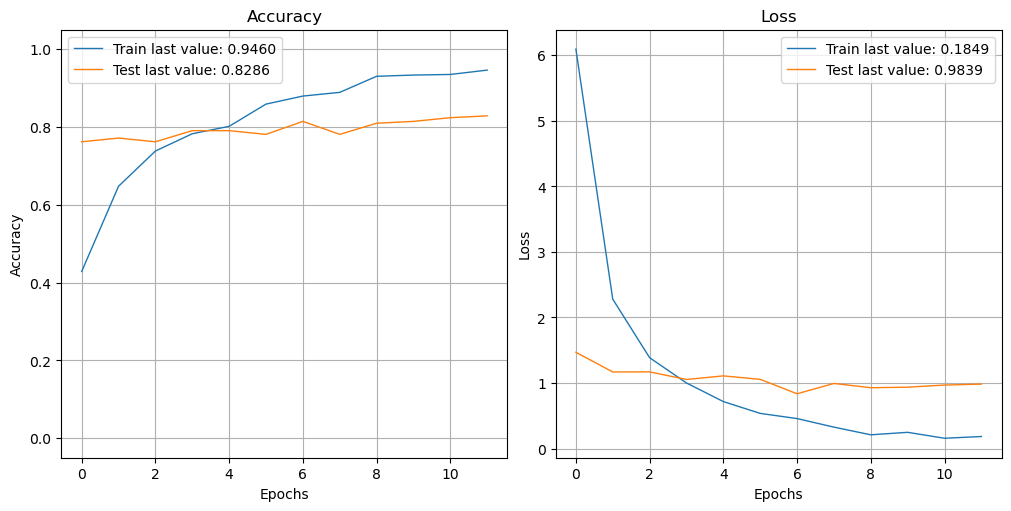

In [14]:
# Affichage de la courbe d'apprentissage de l'accuracy et de la fonction cout
show_history(history1)
plot_history(history1, path="../Output/Courbe_d'apprentissage/Courbe_d'apprentissage_VGG16_1.png")
plt.close()

Les courbes d'apprentissage associées au jeu d'entrainement révèlent que les prédictions s'améliorent significativement au fur et a mesure des différents epochs. Ces observations traduisent une bonne progression de la performance du modèle sur les données d'entrainement. En revanche, on remarque que l'accuracy associé au jeu de validation peine a augmenter et que la fonction cout diminue très peu. Ces résultats quant a eux suggèrent que le modèle a du mal a améliorer sa capacité de généralisation sur les données de validation. Il serait donc intéressant de tester l'introduction d'une forme de régularisation des données pour réduire le surapprentissage. Cela peut être effectuée par une approche de data augmentation. Avant de passer à cette approche, on va analyser plus finament les prédictions faites par ce modèle en analysant la matrice de confusion ainsi que le rapport de classification qui apporte d'autres métrique d'évaluation intéressantes.

In [15]:
# Prédictions des probas de chaque classes pour chaque images
y_test_pred = model1.predict(X_test, verbose=False)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred, axis=1)

# Conversion des catétories réelles en int
y_test = np.argmax(y_test, axis=1)

# Visualisation
print(y_test_pred)
print()
print(y_test)

[6 5 2 5 5 0 6 2 3 2 3 1 4 4 1 3 2 3 4 3 4 1 6 6 4 4 3 0 1 1 3 5 2 0 6 0 0
 6 1 4 3 3 0 2 2 0 5 6 1 0 3 1 3 1 6 6 5 4 4 4 6 6 4 6 0 2 4 1 1 0 2 5 2 1
 1 6 3 5 0 5 4 1 3 0 2 6 4 6 0 2 4 5 4 5 0 4 1 3 2 3 2 4 1 3 0 5 1 3 3 5 2
 6 1 2 0 3 3 5 1 2 5 3 3 5 0 3 2 5 2 2 0 5 5 0 1 6 0 1 0 3 0 5 3 2 3 5 5 3
 3 3 2 1 4 4 5 1 0 6 2 6 3 3 4 1 0 4 0 5 6 1 5 2 1 2 1 1 2 1 4 2 4 1 2 4 2
 4 0 3 2 3 4 5 1 0 2 1 6 4 6 1 5 4 3 6 6 3 2 6 5 6]

[6 5 2 5 5 0 6 2 3 2 3 1 4 0 1 1 2 3 3 3 4 4 6 6 0 4 1 0 5 1 3 3 2 0 6 0 4
 6 6 4 3 2 0 2 2 0 5 6 0 0 3 1 3 1 6 6 1 4 0 4 6 6 4 6 0 2 4 1 1 0 2 5 2 1
 1 6 3 5 4 5 4 1 3 0 2 6 4 6 4 2 4 5 4 5 0 4 1 3 2 3 2 4 1 3 0 5 1 3 0 5 2
 6 1 2 0 2 3 5 1 2 5 0 3 5 0 4 2 5 2 6 0 5 5 0 1 6 0 1 0 0 0 3 3 2 0 5 5 3
 5 3 2 1 1 4 5 1 0 6 2 6 3 3 4 1 3 4 0 3 6 2 5 5 1 5 1 1 6 1 4 6 4 2 2 4 2
 4 0 3 2 5 4 5 1 4 5 3 6 4 6 1 5 4 3 6 6 3 2 6 5 6]


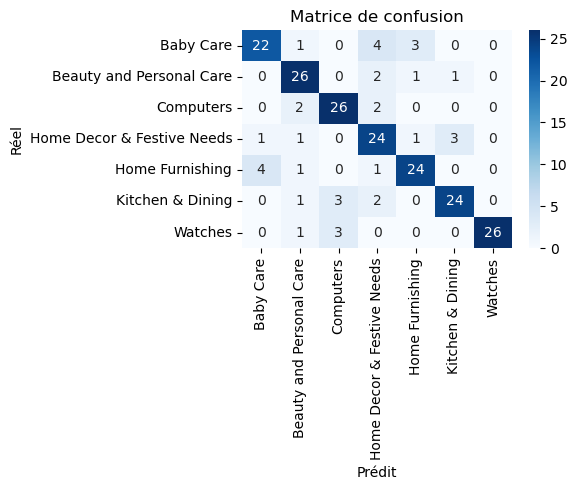

                            precision    recall  f1-score   support

                 Baby Care       0.81      0.73      0.77        30
  Beauty and Personal Care       0.79      0.87      0.83        30
                 Computers       0.81      0.87      0.84        30
Home Decor & Festive Needs       0.69      0.80      0.74        30
           Home Furnishing       0.83      0.80      0.81        30
          Kitchen & Dining       0.86      0.80      0.83        30
                   Watches       1.00      0.87      0.93        30

                  accuracy                           0.82       210
                 macro avg       0.83      0.82      0.82       210
              weighted avg       0.83      0.82      0.82       210



In [16]:
# Définition des labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test, y_test_pred, labels=labels)

# Décodage des catégories
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.title("Matrice de confusion")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_VGG16_1.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test, y_test_pred, target_names=labels))

La matrice de confusion et le rapport de classification confirment que la majorité des catégories ont été bien prédites. On retrouve le score d'exactitude global de 82% qui indiquent que 82% des produits ont été classés dans la bonne catégorie. Le rapport de classification permet également d'accéder au mesure de précision et de rappel. La précision indique, pour chaque catégorie, la proportion de vrais positifs parmi l’ensemble des prédictions positives faites pour cette classe. Le rappel mesure, quant à lui, la proportion de vrais positifs retrouvés parmi tous les produits appartenant réellement à cette classe. 

Les catégories Beauty, Computer, Home Furnishing, Kitchen et Watch présentent à la fois une très bonne précision et un très bon rappel, ce qui suggère qu’elles sont plus faciles à distinguer. À l'inverse, les performances sont légèrement moins bonnes pour les catégories Baby Care (rappel plus faible) et Home Decors (précision plus faible), ce qui laisse penser que ces classes sont plus difficiles à différencier. En  particulier, les produits appartenant à la catégorie baby care mal classés ont principalement été prédis comme des produits de la catégorie Home Furnishing et Home decor. De même, les produits prédits à tort comme étant de la catégorie Home Decors appartiennent en réalité, pour la plupart, à la catégorie Baby Care, mais aussi à d’autres comme Beauty and Personnal care, Computer, Home Furnishing et Kitchen and Dining.

In [17]:
# Création de la dataframe de résultats associés au modèle 1
Resultats_1 = pd.DataFrame({
    'approche': ['model1'],
    'accuracy_train': [accuracy_train_1],
    'accuracy_val': [accuracy_val_1],
    'accuracy_test': [accuracy_test_1],
    "temps d'entraînement": [duration_1]
})

# Affichage de la dataframe de résultats
Resultats_1

,approche,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
0,model1,0.979365,0.814286,0.819048,1180.652231


# Approche 2: Data augmentation avec ImageDatagenerator

Dans cette approche, les images et leurs étiquettes associées sont préparées à partir d’un DataFrame contenant les chemins des fichiers image et les labels correspondants. Les labels sont d'abord convertis en chaînes de caractères afin qu'ils soient compatibles avec la méthode flow_from_dataframe utilisée pour générer les données.

Bien que la méthode flow_from_dataframe permette un découpage automatique entre les jeux d'entraînement et de validation via le paramètre validation_split, ce découpage ne garantit pas un équilibre des classes entre les sous deux ensembles. Pour assurer une bonne représentativité des classes dans les ensembles d'entraînement, de validation et de test, le découpage des dataFrames sera donc réalisé manuellement, en suivant la même approche que précédemment, avec les même proportions que dans la première partie et une stratification des classes.

Dans l'étape suivante, le jeu d'entraînement est traité à l'aide d'un générateur d’images (ImageDataGenerator). Ce générateur permet d'appliquer des augmentations de données telles que des rotations, des translations des flip horizontaux ou encore des changements de luminosité ou de contraste de manière aléatoire pendant l'entraînement. Cette technique permet au modèle de voir des variantes inédites des images d'entraînement à chaque epoch, ce qui revient à enrichir virtuellement le jeu de données. Cette technique contribue donc à réduire le surapprentissage, en exposant le modèle à des images ayant subi des transformations variées, ce qui l’empêche de mémoriser trop spécifiquement les détails des images brutes.

Ce générateur d'image sera uniquement appliquées aux images du jeux d'entrainement. Les jeux de données de validation et de test ne subissent quant à eux aucune augmentation : ils sont uniquement prétraités avec le même prétraitement que celui appliqué aux images d’entraînement en utilisant la même fonction (paramétré pour ne pas inclure la data augmentation).

In [18]:
# Conversion du label en string
Data_image['label'] = Data_image['label'].astype(str)

# Découpage du jeu de données en train et test 
Data_temp, Data_test = train_test_split(
    Data_image, test_size=0.2, stratify=Data_image['label'], random_state=42
)

# Découpage du jeu de données train en train et validation 
Data_train, Data_val = train_test_split(
    Data_temp, test_size=0.25, stratify=Data_temp['label'], random_state=42
)

# Définition du batch size
batch_size = 32

# Création d'un ImageDataGenerator pour le jeu d'entraînement avec prétraitement et augmentation de données
datagen_train = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    validation_split=0,
    preprocessing_function=preprocess_input)

# Création d'un ImageDataGenerator pour le jeu de test et de val avec prétraitement et sans augmentation de données
datagen_test_val = ImageDataGenerator(
    validation_split=0,
    preprocessing_function=preprocess_input)


# Génération des flux de données pour l'entraînement, la validation et le test à partir des DataFrames
train_flow = datagen_train.flow_from_dataframe(Data_train, directory='',
                                x_col='image_path', y_col='label',
                                weight_col=None, target_size=(224, 224),
                                classes=None, class_mode='categorical',
                                batch_size=batch_size, shuffle=True, seed=42)                               

val_flow = datagen_test_val.flow_from_dataframe(Data_val, directory='',
                                x_col='image_path', y_col='label',
                                weight_col=None, target_size=(224, 224),
                                classes=None, class_mode='categorical',
                                batch_size=batch_size, shuffle=True, seed=42)  

test_flow = datagen_test_val.flow_from_dataframe(Data_test, directory='',
                                x_col='image_path', y_col='label',
                                weight_col=None, target_size=(224, 224),
                                classes=None, class_mode='categorical',
                                batch_size=batch_size, shuffle=False, seed=42) 


Found 630 validated image filenames belonging to 7 classes.
Found 210 validated image filenames belonging to 7 classes.
Found 210 validated image filenames belonging to 7 classes.


In [19]:
# Vérification de l'équilibre des classes
print(Counter(train_flow.classes))
print(Counter(val_flow.classes))
print(Counter(test_flow.classes))

Counter({0: 90, 5: 90, 3: 90, 6: 90, 2: 90, 4: 90, 1: 90})
Counter({6: 30, 4: 30, 0: 30, 2: 30, 5: 30, 1: 30, 3: 30})
Counter({0: 30, 1: 30, 4: 30, 6: 30, 3: 30, 5: 30, 2: 30})


Afin de visualiser les transformations effectuées par le générateur d'images, on peut afficher une image brute accompagnée de plusieurs versions de cette même image après augmentation par le générateur.

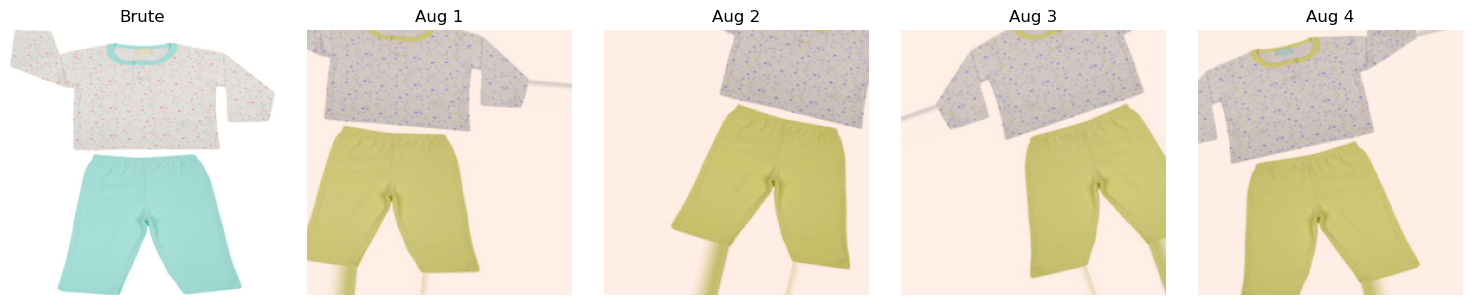

In [20]:
# Chargement d'une image depuis le DataFrame
image_path = Data_train.iloc[0]['image_path']

# Redimensionnement de l'image
img = Image.open(image_path).resize((224, 224))

# Conversion de l'image en array
img_array = np.array(img).astype('float32')

# Ajout d'une dimension pour simuler un batch
img_batch = np.expand_dims(img_array, axis=0)

# Application du générateur pour cette image
gen = datagen_train.flow(img_batch, batch_size=1)

# Initialisation et construction de la figure
plt.figure(figsize=(15, 3))
plt.subplot(1, 5, 1)

# Affichage de l'image brute
plt.imshow(img_array.astype('uint8'))
plt.title("Brute")
plt.axis('off')

# Génération et affichage de 4 versions augmentées de l'image
for i in range(4):
    aug_img = next(gen)[0]
    aug_img = (aug_img - aug_img.min()) / (aug_img.max() - aug_img.min())  
    plt.subplot(1, 5, i + 2)
    plt.imshow(aug_img)
    plt.title(f"Aug {i+1}")
    plt.axis('off')

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde de la figure
plt.savefig(f'../Output/Data_augmentation/Data_augmentation.png', format='png')

# Affichage de la figure
plt.show()


Après passage par le générateur, on observe diverses transformations telles que des rotations, des flips horizontaux, ainsi que des décalages horizontaux et verticaux. Ces augmentations permettent donc bien d'enrichir la variabilité des données d’entraînement, en simulant différentes variations d'une même image tout en conservant les caractéristiques essentielles de l'image d’origine.

Comme pour l'approche précédent, les checkpoints du modèle seront sauvegardés localement et un early stoping sera défini.

In [21]:
# Création du modèle
with tf.device('/gpu:0'): model2 = create_model_fct()

# Définition du chemin de sauvegarde
model2_save_path = "../Models/CNN/VGG16/VGG16_2_best_weights.keras"

# Création d'un callback pour sauvegarder le modèle 
checkpoint = ModelCheckpoint(model2_save_path, monitor='val_loss', verbose=1, save_best_only=True, mode='min')

# Définition d'un early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

# Liste des callbacks
callbacks_list = [checkpoint, es]


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,3

 Total params: 14,847,815 (56.64 MB)

 Trainable params: 133,127 (520.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

None


In [22]:
# Définition du temps avant l'entrainement du modèle
start_2 = time.time()

# Entraînement du modèle sur les données d'entraînement (train_flow)
with tf.device('/gpu:0'): 
    history2 = model2.fit(train_flow,
                    validation_data=val_flow,
                    batch_size=batch_size, epochs=50, callbacks=callbacks_list, verbose=1)
    
# Calcul du temps d'execution de l'entrainement du modèle
duration_2 = time.time() - start_2

C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.3583 - loss: 6.0461
Epoch 1: val_loss improved from inf to 1.51694, saving model to ../Models/CNN/VGG16_2_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 129s 6s/step - accuracy: 0.3636 - loss: 5.9535 - val_accuracy: 0.7762 - val_loss: 1.5169
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7168 - loss: 1.5456
Epoch 2: val_loss improved from 1.51694 to 1.15786, saving model to ../Models/CNN/VGG16_2_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 125s 6s/step - accuracy: 0.7154 - loss: 1.5486 - val_accuracy: 0.8048 - val_loss: 1.1579
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7277 - loss: 1.1949
Epoch 3: val_loss improved from 1.15786 to 0.99791, saving model to ../Models/CNN/VGG16_2_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 122s 6s/step - accuracy: 0.7287 - loss: 1.1929 - val_accuracy: 0.8333 - val_loss: 0.9979
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7216 - loss: 1.05

In [23]:
# Calcul et afficahge des scores d'accuracy sur le dernier epoch
print("Score d'accuracy sur le dernier epoch")
print("---------------------------------------")
loss, accuracy = model2.evaluate(train_flow, verbose=False)
print("Training Accuracy:    {:.4f}".format(accuracy))
loss, accuracy = model2.evaluate(val_flow, verbose=False)
print("Validation Accuracy:  {:.4f}".format(accuracy))
loss, accuracy = model2.evaluate(test_flow, verbose=False)
print("Test Accuracy:        {:.4f}".format(accuracy))

Score d'accuracy sur le dernier epoch
---------------------------------------
Training Accuracy:    0.9778
Validation Accuracy:  0.8667
Test Accuracy:        0.8095


In [24]:
# Chargement des poids de l'epoch optimal
model2 = load_model(model2_save_path)

# Calcul et affichage des scores d'accuracy sur l'epoch optimal
print("Score d'accuracy sur l'epoch optimal")
print("---------------------------------------")
loss_train_2, accuracy_train_2 = model2.evaluate(train_flow, verbose=False)
print("Train Accuracy:      {:.4f}".format(accuracy_train_2))
loss_val_2, accuracy_val_2 = model2.evaluate(val_flow, verbose=False)
print("Validation Accuracy: {:.4f}".format(accuracy_val_2))
loss_test_2, accuracy_test_2 = model2.evaluate(test_flow, verbose=False)
print("Test Accuracy:       {:.4f}".format(accuracy_test_2))

Score d'accuracy sur l'epoch optimal
---------------------------------------
Train Accuracy:      0.9476
Validation Accuracy: 0.8190
Test Accuracy:       0.7714


À l’epoch optimal, le modèle présente une accuracy de **94,76 %** sur l’ensemble d’entraînement, ce qui indique un bon apprentissage des données. L’accuracy sur l’ensemble de validation est de **81,90 %** mais diminue à **77,14 %** sur le jeu de test. On constate donc une diminution du surapprentissage sur le jeu de validation par rapport à la première approche (Ecart de **12.9** entre l'accuracy mesurée sur les données d'entrainement et celle mesurée sur les données de validation pour cette approche contre **16.5** lors de l'approche 1). En rechanche, la généralisation sur les données de test s'avèrent moins bonne ce qui suggère que le modèle s'ajuste peut être un peu trop aux spécifités du jeu de validation ou que les données de test présentent des caractéristiques différentes.

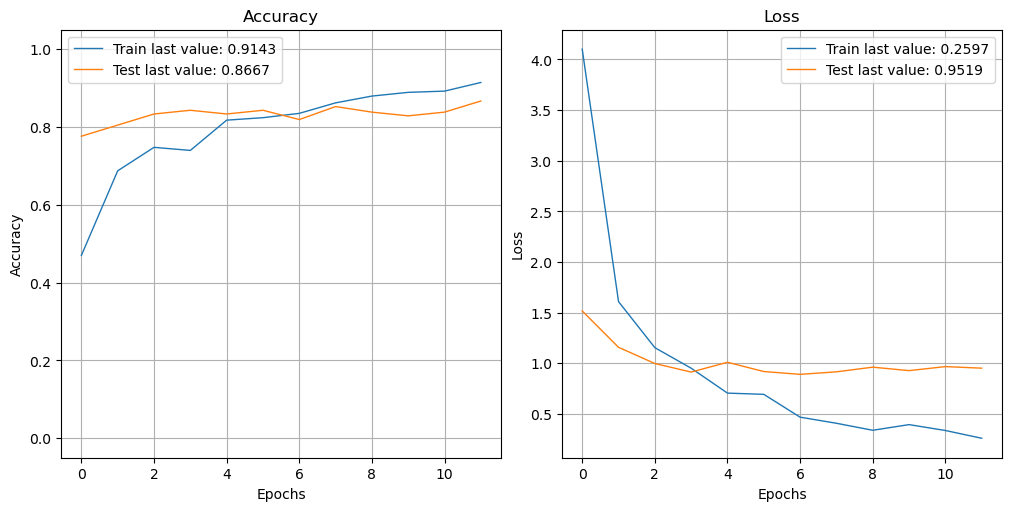

In [25]:
# Affichage de la courbe d'apprentissage de l'accuracy et de la fonction cout
show_history(history2)
plot_history(history2, path="../Output/Courbe_d'apprentissage/Courbe_d'apprentissage_VGG16_2.png")
plt.close()

A nouveau, on observe une amélioration importante de l’accuracy sur le jeu de données d’entraînement, qui passe d’environ 0.42 à près de 0.95 après 10 epochs. L’accuracy sur le jeu de validation progresse également, mais de manière plus modérée: elle démarre à un niveau déjà élevé (environ 0.78) et atteint 0.86 en fin d'entraînement.
On note donc un écart modéré entre les performances sur les jeux d'entraînement et de validation, mais celui ci apparait moins marqué que celui observé lors de la première approche.
Concernant la fonction de coût, on observe une diminution rapide de la perte sur le jeu d’entraînement, tandis que celle du jeu de validation diminue plus lentement et tend à se stabiliser autour de l’epoch 4-5.
Cela suggère un début de surapprentissage, bien que celui ci reste faible pour cette approche.

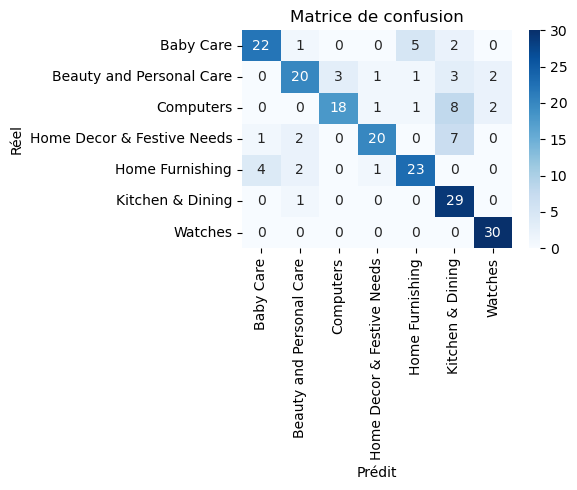

                            precision    recall  f1-score   support

                 Baby Care       0.81      0.73      0.77        30
  Beauty and Personal Care       0.77      0.67      0.71        30
                 Computers       0.86      0.60      0.71        30
Home Decor & Festive Needs       0.87      0.67      0.75        30
           Home Furnishing       0.77      0.77      0.77        30
          Kitchen & Dining       0.59      0.97      0.73        30
                   Watches       0.88      1.00      0.94        30

                  accuracy                           0.77       210
                 macro avg       0.79      0.77      0.77       210
              weighted avg       0.79      0.77      0.77       210



In [26]:
# Prédictions des probas de chaque classes pour chaque images
y_test_pred_proba = model2.predict(test_flow, verbose=0)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred_proba, axis=1) 

# Extraction des vrais catégories 
y_test_true = test_flow.classes 

# Définition des labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test_true, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test_true, y_test_pred, labels=labels)

# Décodage des catégories
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.title("Matrice de confusion")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_VGG16_2.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test_true, y_test_pred, target_names=labels))

La matrice de confusion ainsi que le rapport de classification montrent une performance globale du modèle sur les données teste un peu moins bonne que lors de la première approche, avec un score d'accuracy de 0.77. 

On note un rappel parfait pour les produits de la catégorie Watch ce qui indique que tous les produits appartenant réellement à cette catégorie ont bien été détectés par le modèle. Un bon rappel a aussi été observé pour les produits des catégories Home furnishing et Kitchen and Dining. Concernant la précision, on observe de très bons résultats pour les catégories Baby care, Computers, Home decor et Watch. En revanche, la catégorie Kitchen and Dining est caractérisé par une précision plutôt moyenne ce qui suggèrent que le modèle a eu tendance à prédire cette catégorie à tort pour certains produits n’en faisant pas partie. La matrice de confusion indique qu'il s'agit principalement des produits des catégories Computer et Home decor. 

In [27]:
# Création de la dataframe de résultats associé au modèle 2
Resultats_2 = pd.DataFrame({
    'approche': ['model2'],
    'accuracy_train': [accuracy_train_2],
    'accuracy_val': [accuracy_val_2],
    'accuracy_test': [accuracy_test_2],
    "temps d'entraînement": [duration_2]
})

# Ajout des résulats du modèle 2 dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats_1, Resultats_2])

# Affichage de la dataframe de résultats
Resultats 

,approche,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
0,model1,0.979365,0.814286,0.819048,1180.652231
0,model2,0.947619,0.819048,0.771429,1513.871977


# Approche 3: Approche par Dataset sans data augmentation

La troisième approche qui va être explorée consiste à charger les images directement à partir du répertoire local avec la fonction image_dataset_from_directory de Keras qui permet de charger de facon efficace et optimisée des jeux de données d'images dans TenserFlow sans passer par une dataframe. 

Pour cela  les images vont être réorganisées physiquement dans des sous dossiers classés par labels afin de pouvoir utiliser la fonction. Dans un premier temps un dossier train, un dossier val et un dossier test seront créés et chacun contiendront les sous dossiers nomées selon les catégories contenant les images de ces catégories. Une fois cette structure mise en place, les images seront chargées de façon automatique grâce à la fonction image_dataset_from_directory. Les labels seront inférés à partir des noms des sous dossiers et en parraelle, les images seront redimensionnées et batchés de facon automatique. 

Les images seront copiées dans les bons sous dossiers à l'aide d'une fonction qui sera définie ci dessous. 

In [28]:
def copy_image_to_class_folder(old_path, label, base_dir):
    
    """
    Copie une image vers un sous dossier correspondant à sa classe dans un dossier de base.

    Paramètres
        old_path (str): Chemin de l'image à copier.
        label (str): Nom de la catégorie associée à l'image.
        base_dir (str): Chemin du dossier de destination principal où seront créés les sous dossiers par classe.

    Retour
        new_path (str): Nouveau chemin de l'image copiée.
    """
    # Création du chemin du sous dossier correspondant à la classe
    class_dir = os.path.join(base_dir, label)
    os.makedirs(class_dir, exist_ok=True)
    
    # Détermination du nom du fichier et du chemin de destination
    filename = os.path.basename(old_path)
    new_path = os.path.join(class_dir, filename)
    
    # Copie du fichier vers le nouveau chemin
    try:
        shutil.copy2(old_path, new_path)
        return new_path
    except FileNotFoundError:
        print(f"Image introuvable : {old_path}")
        return None

In [29]:
# Définition du batch size
batch_size = 32

# Nouveau dossier de destination pour les images du jeu d'entrainement
Path_train = './Data/Image_train'
os.makedirs(Path_train, exist_ok=True) 

# Nouveau dossier de destination pour les images du jeu de validation
Path_val = './Data/Image_val'
os.makedirs(Path_val, exist_ok=True) 

# Nouveau dossier de destination pour les images du jeu de test
Path_test = './Data/Image_test'
os.makedirs(Path_test, exist_ok=True) 

# Copie des images du eu train dans les sous dossiers par classes dans le dossier Iamge_train
Data_train['new_image_path'] = Data_train.apply(
    lambda row: copy_image_to_class_folder(row['image_path'], row['label'], Path_train),
    axis=1
)

# Copie des images du val dans les sous dossiers par classes dans le dossier Iamge_val
Data_val['new_image_path'] = Data_val.apply(
    lambda row: copy_image_to_class_folder(row['image_path'], row['label'], Path_val),
    axis=1
)

# Copie des images du jeu test dans les sous dossiers par classes dans le dossier Iamge_test
Data_test['new_image_path'] = Data_test.apply(
    lambda row: copy_image_to_class_folder(row['image_path'], row['label'], Path_test),
    axis=1
)


# Chargement et préparation automatique des jeu de données de train, de validation et de test
dataset_train =  tf.keras.utils.image_dataset_from_directory(
        Path_train, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de train, de validation et de test
dataset_val =  tf.keras.utils.image_dataset_from_directory(
        Path_val, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de train, de validation et de test
dataset_test =  tf.keras.utils.image_dataset_from_directory(
        Path_test, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=False, 
        seed=42)


Found 630 files belonging to 7 classes.
Found 210 files belonging to 7 classes.
Found 210 files belonging to 7 classes.


In [30]:
# Compte du nombre de labels par classe
y_train = np.concatenate([labels.numpy() for _, labels in dataset_train])
y_train_true = np.argmax(y_train, axis=1)

# Compte du nombre de labels par classe
y_val = np.concatenate([labels.numpy() for _, labels in dataset_val])
y_val_true = np.argmax(y_val, axis=1)

# Compte du nombre de labels par classe
y_test = np.concatenate([labels.numpy() for _, labels in dataset_test])
y_test_true = np.argmax(y_test, axis=1)

# Vérification de l'équilibre des classes
print(Counter(y_train_true))
print(Counter(y_val_true))
print(Counter(y_test_true))

Counter({2: 90, 3: 90, 0: 90, 6: 90, 1: 90, 4: 90, 5: 90})
Counter({6: 30, 1: 30, 2: 30, 0: 30, 4: 30, 5: 30, 3: 30})
Counter({0: 30, 1: 30, 2: 30, 3: 30, 4: 30, 5: 30, 6: 30})


In [31]:
# Création du modèle
with tf.device('/gpu:0'): 
    model3 = create_model_fct()

# Définition du chemin de sauvegarde
model3_save_path = "../Models/CNN/VGG16/VGG16_3_best_weights.keras"

# Création d'un callback pour sauvegarder le modèle 
checkpoint = ModelCheckpoint(model3_save_path, monitor='val_loss', verbose=1, save_best_only=True, mode='min')

# Définition d'un early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

# Liste des callbacks
callbacks_list = [checkpoint, es]

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         131,3

 Total params: 14,847,815 (56.64 MB)

 Trainable params: 133,127 (520.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

None


In [32]:
# Définition du temps avant l'entrainement du modèle
start_3 = time.time()

# Entraînement du modèle sur les données d'entraînement (dataset_train)
with tf.device('/gpu:0'): 
    history3 = model3.fit(dataset_train,
                    validation_data=dataset_val,
                    batch_size=batch_size, epochs=50, callbacks=callbacks_list, verbose=1)

# Calcul du temps d'execution de l'entrainement du modèle
duration_3 = time.time() - start_3

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3561 - loss: 9.0007
Epoch 1: val_loss improved from inf to 1.60107, saving model to ../Models/CNN/VGG16_3_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 105s 5s/step - accuracy: 0.3618 - loss: 8.8656 - val_accuracy: 0.7429 - val_loss: 1.6011
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6566 - loss: 2.6327
Epoch 2: val_loss improved from 1.60107 to 1.13785, saving model to ../Models/CNN/VGG16_3_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 103s 5s/step - accuracy: 0.6576 - loss: 2.6239 - val_accuracy: 0.8000 - val_loss: 1.1378
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7330 - loss: 1.7017
Epoch 3: val_loss improved from 1.13785 to 0.99848, saving model to ../Models/CNN/VGG16_3_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 103s 5s/step - accuracy: 0.7337 - loss: 1.6919 - val_accuracy: 0.7952 - val_loss: 0.9985
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7985 - loss: 0.81

In [33]:
# Calcul et afficahge des scores d'accuracy sur le dernier epoch
print("Score d'accuracy sur le dernier epoch")
print("---------------------------------------")
loss, accuracy = model3.evaluate(dataset_train, verbose=False)
print("Training Accuracy:    {:.4f}".format(accuracy))
loss, accuracy = model3.evaluate(dataset_val, verbose=False)
print("Validation Accuracy:  {:.4f}".format(accuracy))
loss, accuracy = model3.evaluate(dataset_test, verbose=False)
print("Test Accuracy:        {:.4f}".format(accuracy))

Score d'accuracy sur le dernier epoch
---------------------------------------
Training Accuracy:    0.9984
Validation Accuracy:  0.8190
Test Accuracy:        0.7762


In [34]:
# Chargement des poids de l'epoch optimal
model3 = load_model(model3_save_path)

# Calcul et affichage des scores d'accuracy sur l'epoch optimal
print("Score d'accuracy sur l'epoch optimal")
print("---------------------------------------")
loss_train_3, accuracy_train_3 = model3.evaluate(dataset_train, verbose=False)
print("Train Accuracy:      {:.4f}".format(accuracy_train_3))
loss_val_3, accuracy_val_3 = model3.evaluate(dataset_val, verbose=False)
print("Validation Accuracy: {:.4f}".format(accuracy_val_3))
loss_test_3, accuracy_test_3 = model3.evaluate(dataset_test, verbose=False)
print("Test Accuracy:       {:.4f}".format(accuracy_test_3))


Score d'accuracy sur l'epoch optimal
---------------------------------------
Train Accuracy:      0.9365
Validation Accuracy: 0.8143
Test Accuracy:       0.7524


À l’epoch optimal, le modèle présente une accuracy de **93,65 %** sur l’ensemble d’entraînement, ce qui indique un bon apprentissage des données. L’accuracy sur l’ensemble de validation est de **81,43 %** et diminue à **75.24 %** sur le jeu de test. Dans cette nouvelle approche n'intégrant pas de data augmentation on retrouve une différence de **12** entre l'accuracy mesurée sur les données d'entrainement et l'accuracy mesurée sur les données de validation indiquant à nouveau l'existence d'un surapprentissage. 

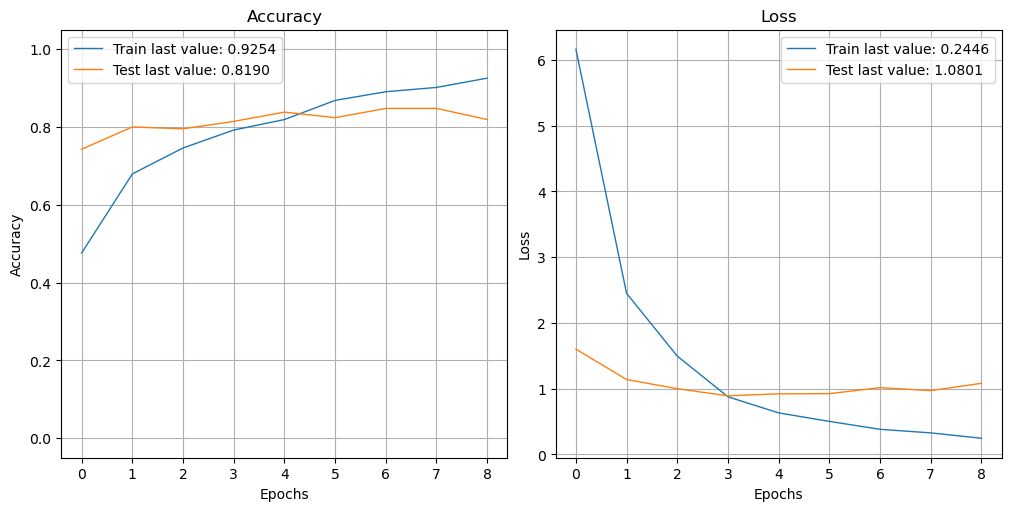

In [35]:
# Affichage de la courbe d'apprentissage de l'accuracy et de la fonction cout
show_history(history3)
plot_history(history3, path="../Output/Courbe_d'apprentissage/Courbe_d'apprentissage_VGG16_3.png")
plt.close()

Lorsque les images sont chargées depuis le répertoire sans data augmentation, on retrouve une évolution des courbes d’apprentissage similaire à celle observée dans la première approche. Le modèle progresse bien sur les données d’entraînement, mais montre des signes de surapprentissage, avec une stagnation de l’accuracy sur la validation et une baisse limitée de la fonction de coût. La encore, il serait intéressant d'envisaber d'ajouter une étape de data augmentation pour améliorer la généralisation du modèle.

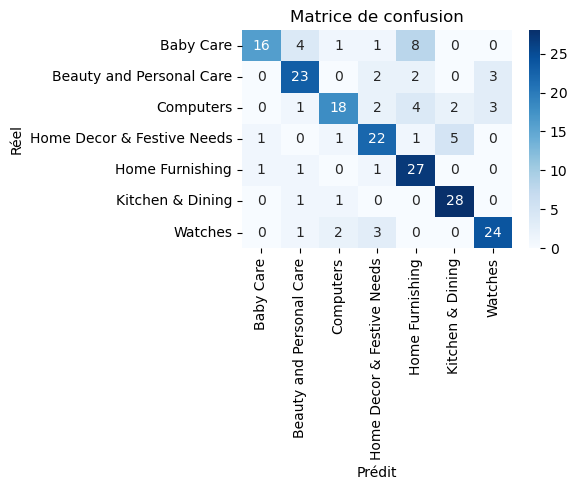

                            precision    recall  f1-score   support

                 Baby Care       0.89      0.53      0.67        30
  Beauty and Personal Care       0.74      0.77      0.75        30
                 Computers       0.78      0.60      0.68        30
Home Decor & Festive Needs       0.71      0.73      0.72        30
           Home Furnishing       0.64      0.90      0.75        30
          Kitchen & Dining       0.80      0.93      0.86        30
                   Watches       0.80      0.80      0.80        30

                  accuracy                           0.75       210
                 macro avg       0.77      0.75      0.75       210
              weighted avg       0.77      0.75      0.75       210



In [36]:
# Prédictions des probas de chaque classes pour chaque images
y_test_pred_proba = model3.predict(dataset_test, verbose=0)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred_proba, axis=1) 

# Définition fes labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test_true, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test_true, y_test_pred, labels=labels)

# Décodage des catégorie
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_VGG16_3.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test_true, y_test_pred, target_names=labels))

La matrice de confusion ainsi que le rapport de classification montrent que le modèle a une bonne performance globale caractérisée par une exactitude moyenne de 75% sur les données tests.

La catégorie Baby Care présente le meilleur score de précision, ce qui signifie que, parmi les produits prédits comme appartenant à cette catégorie, une grande majorité sont effectivement corrects. Le meilleur score de rappel est quant à lui observé pour la catégorie Kitchen & Dining, indiquant que la plupart des produits appartenant réellement à cette catégorie ont bien été identifiés comme tels par le modèle. En revanche, la catégorie Beauty and Personnal Care est caractérisée par des scores parmis les plus faibles à la fois en précision et en rappel. Cela peut indiquer que le modèle a eu des difficultés à reconnaître correctement les produits de cette catégorie, soit en les confondant avec des produits d'autres catégories, soit en échouant dans leur prédiction.

In [37]:
# Création de la dataframe de résultats associés au modèle 3
Resultats_3 = pd.DataFrame({
    'approche': ['model3'],
    'accuracy_train': [accuracy_train_3],
    'accuracy_val': [accuracy_val_3],
    'accuracy_test': [accuracy_test_3],
    "temps d'entraînement": [duration_3]
})

# Ajout des résulats du modèle 3 dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_3])

# Affichage de la dataframe des résultats
Resultats

,approche,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
0,model1,0.979365,0.814286,0.819048,1180.652231
0,model2,0.947619,0.819048,0.771429,1513.871977
0,model3,0.936508,0.814286,0.752381,925.676806


# Approche 4: Approche par Dataset avec data augmentation intégrée au modèle

La dernière approche reprendra le principe de chargement et préparation automatique des images de l'approche précédente mais cette fois une étape de data augmentation sera appliquée par le modèle. L'augmentation de données sera implémentée sous la forme d'une couche qui sera ajoutée au modèle de réseau de neurones via la méthode Sequential. Ainsi les transformation de data augmentation seront appliquées de façon dynamique au moment de l'entrainement. Pour mettre tout cela en place, une nouvelle fonction sera définie pour créer le nouveau modèle.

In [38]:
def create_model_fct2() :
    
    """
    Crée et compile un modèle de classification d'images basé sur VGG16 avec data augmentation.

    Le modèle utilise une architecture séquentielle comprenant :
    - Un bloc de data augmentation (flip horizontal, rotation aléatoire, zoom aléatoire),
    - Un rescaling pour centrer les pixels autour de zéro ([-1, 1]),
    - Le modèle VGG16 pré-entraîné (couches gelées, sans le bloc de classification),
    - Une couche de pooling global (GlobalAveragePooling2D),
    - Une couche dense de 256 neurones avec activation ReLU,
    - Une couche Dropout (0.5) pour régularisation,
    - Une couche de sortie dense à 7 neurones avec activation softmax pour classification multi classes.

    Le modèle est compilé avec 
    -l'optimiseur Adam, 
    -la perte categorical_crossentropy,
    -la métrique accuracy

    Sortie:
        model (keras.Sequential): Le modèle Keras compilé, prêt à l'entraînement.
    """
        
    # Paramétrage de la data augmentation souhaité
    data_augmentation = Sequential([
        Input(shape=(224, 224, 3)),
        RandomFlip("horizontal"),
        RandomRotation(0.1),
        RandomZoom(0.1)      ])
    
    # Chargement du modèle pré-entraîné    
    model_base = VGG16(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    
    # Gel des couches convolutionnelles (toutes les couches de VGG16 sont mise en non entrainable)
    for layer in model_base.layers:
        layer.trainable = False

    # Définition du nouveau modèle
    model = Sequential([
                data_augmentation,
                Rescaling(1./127.5, offset=-1),
                model_base,
                GlobalAveragePooling2D(),
                Dense(256, activation='relu'),
                Dropout(0.5),
                Dense(7, activation='softmax')
                ])

    # compilation du modèle 
    model.compile(loss="categorical_crossentropy", optimizer='adam', metrics=["accuracy"])

    # Affichage de l'architecture du modèle
    print(model.summary())
    
    return model
    

In [39]:
# Défintion du batch size
batch_size = 32

# Chargement et préparation automatique des jeu de données d'entrainement
dataset_train =  tf.keras.utils.image_dataset_from_directory(
        Path_train, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de validation
dataset_val =  tf.keras.utils.image_dataset_from_directory(
        Path_val, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de test
dataset_test =  tf.keras.utils.image_dataset_from_directory(
        Path_test, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=False, 
        seed=42)

Found 630 files belonging to 7 classes.
Found 210 files belonging to 7 classes.
Found 210 files belonging to 7 classes.


In [40]:
# Création du modèle
with tf.device('/gpu:0'): model4 = create_model_fct2()

# Définition du chemin de sauvegarde
model4_save_path =  "../Models/CNN/VGG16/VGG16_4_best_weights.keras"

# Création d'un callback pour sauvegarder le modèle 
checkpoint = ModelCheckpoint(model4_save_path, monitor='val_loss', verbose=1, save_best_only=True, mode='min')

# Définition d'un early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

# Liste des callbacks
callbacks_list = [checkpoint, es]

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 7)                   │           1,799 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,847,815 (56.64 MB)

 Trainable params: 133,127 (520.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

None


In [41]:
# Définition du temps avant l'entrainement du modèle
start_4 = time.time()

# Entraînement du modèle sur les données d'entraînement (dataset_train)
with tf.device('/gpu:0'): 
    history4 = model4.fit(dataset_train,
                    validation_data=dataset_val,
                    batch_size=batch_size, epochs=50, callbacks=callbacks_list, verbose=1)
    
# Calcul du temps d'execution de l'entrainement du modèle
duration_4 = time.time() - start_4

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1948 - loss: 2.1403
Epoch 1: val_loss improved from inf to 1.42476, saving model to ../Models/CNN/VGG16_4_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 114s 6s/step - accuracy: 0.1973 - loss: 2.1314 - val_accuracy: 0.6524 - val_loss: 1.4248
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5143 - loss: 1.4693
Epoch 2: val_loss improved from 1.42476 to 1.07224, saving model to ../Models/CNN/VGG16_4_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 111s 6s/step - accuracy: 0.5144 - loss: 1.4675 - val_accuracy: 0.7429 - val_loss: 1.0722
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6299 - loss: 1.2209
Epoch 3: val_loss improved from 1.07224 to 0.87731, saving model to ../Models/CNN/VGG16_4_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 110s 6s/step - accuracy: 0.6304 - loss: 1.2184 - val_accuracy: 0.7857 - val_loss: 0.8773
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6638 - loss: 1.05

In [42]:
# Calcul et afficahge des scores d'accuracy sur le dernier epoch
print("Score d'accuracy sur le dernier epoch")
print("---------------------------------------")
loss, accuracy = model4.evaluate(dataset_train, verbose=False)
print("Training Accuracy:    {:.4f}".format(accuracy))
loss, accuracy = model4.evaluate(dataset_val, verbose=False)
print("Validation Accuracy:  {:.4f}".format(accuracy))
loss, accuracy = model4.evaluate(dataset_test, verbose=False)
print("Test Accuracy:        {:.4f}".format(accuracy))

Score d'accuracy sur le dernier epoch
---------------------------------------
Training Accuracy:    0.8810
Validation Accuracy:  0.8286
Test Accuracy:        0.7476


In [43]:
# Chargement des poids de l'epoch optimal
model4 = load_model(model4_save_path)

# Calcul et affichage des scores d'accuracy sur l'epoch optimal
print("Score d'accuracy sur l'epoch optimal")
print("---------------------------------------")
loss_train_4, accuracy_train_4 = model4.evaluate(dataset_train, verbose=False)
print("Train Accuracy:      {:.4f}".format(accuracy_train_4))
loss_val_4, accuracy_val_4 = model4.evaluate(dataset_val, verbose=False)
print("Validation Accuracy: {:.4f}".format(accuracy_val_4))
loss_test_4, accuracy_test_4 = model4.evaluate(dataset_test, verbose=False)
print("Test Accuracy:       {:.4f}".format(accuracy_test_4))

Score d'accuracy sur l'epoch optimal
---------------------------------------
Train Accuracy:      0.8746
Validation Accuracy: 0.8286
Test Accuracy:       0.7714


À l’epoch optimal, le modèle présente une accuracy de **87,46 %** sur l’ensemble d’entraînement, ce qui indique un bon apprentissage des données. L’accuracy sur l’ensemble de validation est de **82,86 %** et diminue à **77,14 %** sur le jeu de test. 
L'ajout d'une étape de Data augmentation directement intégré dans le modèle a permis de réduire de façon plus importante le surapprentissage du modèle. En effet, l’écart entre l’accuracy sur les données d’entraînement et celle sur la validation n’est plus que de **4.6**, contre **17** lorsque la data augmentation n’était pas utilisée. Pour rappel l'écart entre l'accurracy sur les données d'entrainement et celle sur la validation était de  pour l'approche 1 sans data augmentation et de pour l'approche 2 avec augmentation était de **16.5** et **12.9** respectivement.

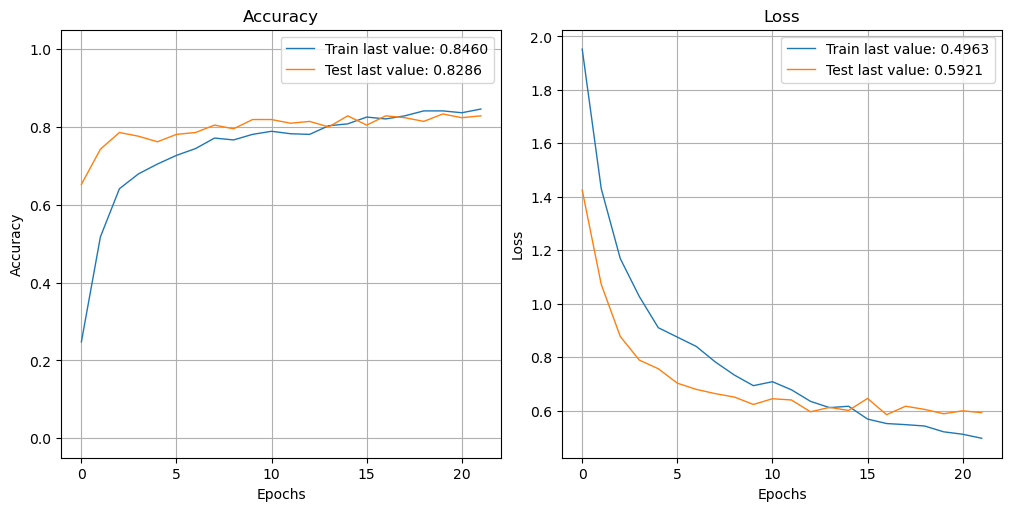

In [44]:
# Affichage de la courbe d'apprentissage de l'accuracy et de la fonction cout
show_history(history4)
plot_history(history4, path="../Output/Courbe_d'apprentissage/Courbe_d'apprentissage_VGG16_4.png")
plt.close()

Lorsque les images sont directement chargées depuis le répertoire et qu’une étape de data augmentation est intégrée dans le modèle, on observe pour la première fois une diminution de la fonction de coût sur les données de validation dès les premiers epochs, avant une stabilisation autour du 10e epoch. Par ailleurs, l’accuracy sur l’ensemble de validation progresse de manière légèrement plus marquée que dans les autres configurations testées. Au final, l’écart entre les accuracy obtenues sur les jeux de validation et d’entraînement est significativement réduit, ce qui témoigne d’un meilleur pouvoir de généralisation du modèle.

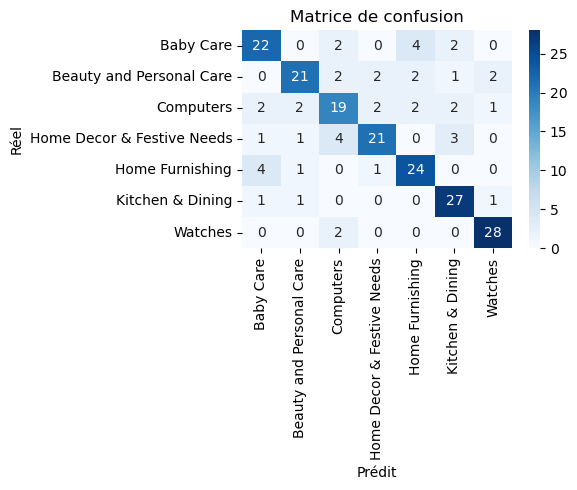

                            precision    recall  f1-score   support

                 Baby Care       0.73      0.73      0.73        30
  Beauty and Personal Care       0.81      0.70      0.75        30
                 Computers       0.66      0.63      0.64        30
Home Decor & Festive Needs       0.81      0.70      0.75        30
           Home Furnishing       0.75      0.80      0.77        30
          Kitchen & Dining       0.77      0.90      0.83        30
                   Watches       0.88      0.93      0.90        30

                  accuracy                           0.77       210
                 macro avg       0.77      0.77      0.77       210
              weighted avg       0.77      0.77      0.77       210



In [45]:
# Prédictions des probas de chaque classes pour chaque images
y_test_pred_proba = model4.predict(dataset_test, verbose=0)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred_proba, axis=1) 

# Définition des labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test_true, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test_true, y_test_pred, labels=labels)

# Décodage des catégorie
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_VGG16_4.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test_true, y_test_pred, target_names=labels))

La matrice de confusion ainsi que le rapport de classfication montre que le modèle a également obtenu une bonne performance caractérisée par une accuracy de 77% sur les données test.

Les scores observés pour la précision et le rappel sont globalement plus homogènes entre les différentes catégories que dans les analyses précédentes. La catégorie Watch se démarque à nouveau avec à la fois la meilleure précision et le meilleur rappel obtenu. A l'inverse la catégorie Computer est la catégorie qui présente les moins bon scores avec une précision de 66% et un rappel de 63%. Les produits appartenant réellement a cette catégorie ont été prédits dans chacune des autres catégorie de facon équitable. En revanche, les produits prédits à tort comme appartenant à la catégorie Computer proviennent majoritairement de la catégorie Home Decor.

En résumé, le modèle propose des performances globalement très satisfaisante avec un bon compromis entre précision et rappel.

In [46]:
# Création de la dataframe de résultats associés au modèle 3
Resultats_4 = pd.DataFrame({
    'approche': ['model4'],
    'accuracy_train': [accuracy_train_4],
    'accuracy_val': [accuracy_val_4],
    'accuracy_test': [accuracy_test_4],
    "temps d'entraînement": [duration_4]
})

# Ajout des résulats du modèle 2 dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_4])

# Affichage de la dataframe de résultats
Resultats

,approche,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
0,model1,0.979365,0.814286,0.819048,1180.652231
0,model2,0.947619,0.819048,0.771429,1513.871977
0,model3,0.936508,0.814286,0.752381,925.676806
0,model4,0.874603,0.828571,0.771429,2374.046259


# Comparaison des différentes approches

In [47]:
def plot_resultats_modeles(df_resultats, ordre_score_approche, dict_couleurs, save_name):
    """
    Génère un barplot comparant les performances de plusieurs approches de modèles
    en termes d'accuracy (train, validation, test) et de temps d'entraînement.

    Paramètres
        df_resultats (pandas.DataFrame) :DataFrame contenant les résultats des modèles avec au minimum les colonnes :
                - approche: nom de l'approche de modélisation
                - accuracy_train, accuracy_val, accuracy_test: scores d'accuracy
                - temps d'entraînement: durée d'entraînement du modèle
        ordre_score_approche (list of str): Liste ordonnée des combinaisons Score_Approche à utiliser pour organiser les barres dans le barplot.
        dict_couleurs (dict): Dictionnaire associant une couleur à chaque Score_Approche.
        save_name(str): Nom de sauvegarde de la figure

    Retour
        p : plotnine.ggplot: barplot construit
    """
    
    # Reformatage de la table de résultat en format long
    resultats_pivot = pd.melt(
        df_resultats,
        id_vars='approche',
        value_vars=['accuracy_train', 'accuracy_val', 'accuracy_test', "temps d'entraînement"],
        var_name='Score',
        value_name='Value')

    # Ajout d'une colonne pour distinguer les types de métriques
    resultats_pivot['Metric'] = resultats_pivot['Score'].apply(
        lambda x: 'Accuracy' if 'accuracy' in x else 'Temps')

    # Simplification des noms pour affichage
    resultats_pivot['Score'] = resultats_pivot['Score'].replace({
        'accuracy_train': 'Train',
        'accuracy_val': 'Validation',
        'accuracy_test': 'Test',
        "temps d'entraînement": "Temps d'entraînement"})

    # Création d'une variable qui sera utilisée pour colorer les barres du barplot
    resultats_pivot['Score_Approche'] = resultats_pivot.apply(
        lambda row: f"{row['Score']}_{row['approche']}", axis=1)

    # Conversion de la variable Score Approche en variable catégorielle
    resultats_pivot['Score_Approche'] = pd.Categorical(
        resultats_pivot['Score_Approche'],
        categories=ordre_score_approche,
        ordered=True)

    # Création de la colonne label
    resultats_pivot['label'] = resultats_pivot['Score'].map({
        'Train': 'Train',
        'Validation': 'Val',
        'Test': 'Test'})

    # Création d'une dataframe qui sera utilisée pour ajouter un label en dessous des barres d'accuracy du barplot
    df_labels = resultats_pivot[resultats_pivot['Metric'] == 'Accuracy'].copy()
    
    # Calcul de la position y pour les labels
    df_labels['y_label'] = -0.05

    # Construction du graphique
    p = (
        ggplot(resultats_pivot, aes(x='approche', y='Value', fill='Score_Approche')) +
        geom_bar(stat='identity', position='dodge') +
        geom_text(
            data=df_labels,
            mapping=aes(x='approche', y='y_label', label='label', group='Score_Approche'),
            position=position_dodge(width=0.9),
            size=10
        ) +
        facet_wrap('~Metric', ncol=1, scales='free_y') +
        scale_fill_manual(values=dict_couleurs) +
        theme(
            figure_size=(12, 8),
            strip_text=element_text(size=12, weight='bold'),
            legend_position='none'
        ) +
        labs(
            y='Valeur',
            x='Approche',
            title='Performance des modèles : accuracy, temps'
        )
    )
    
    # Sauvegarde de la figure
    p.save(f"../Output/Comparaison_modèles/{save_name}", dpi=300)

    return p


C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:615: PlotnineWarning: Saving 12 x 8 in image.
C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:616: PlotnineWarning: Filename: ../Output/Comparaison_modèles/Comparaison_approches


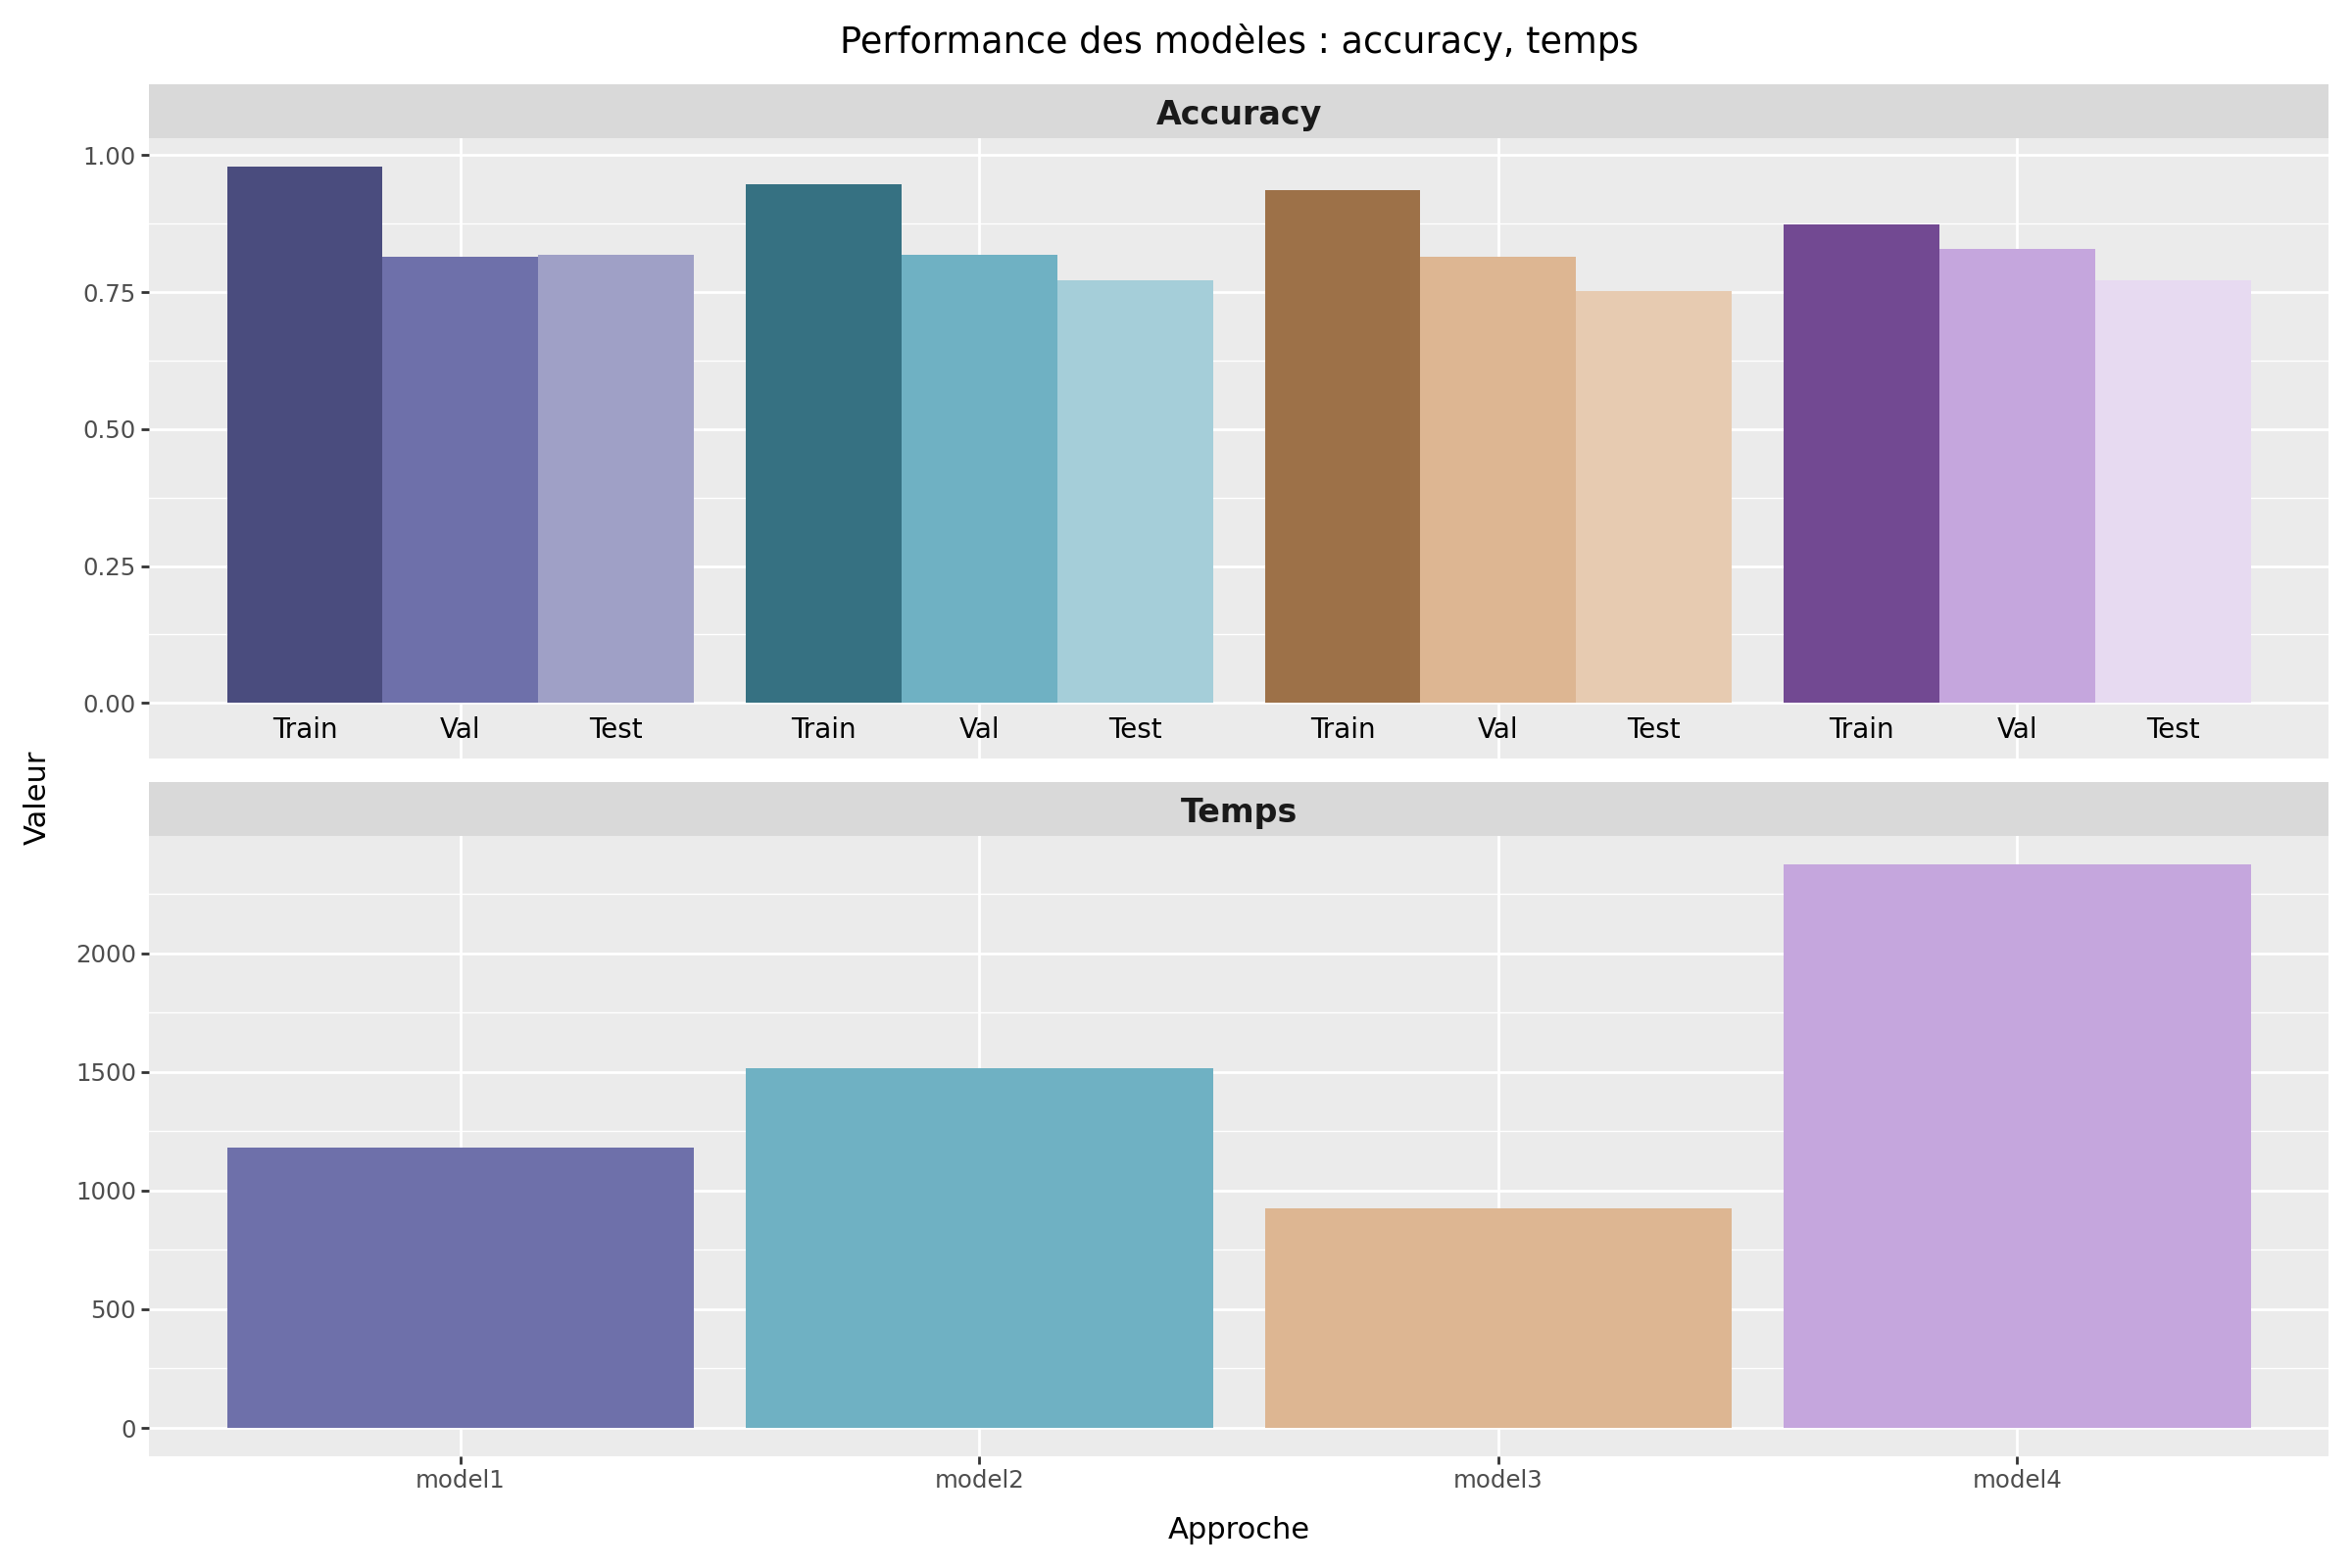

In [48]:
# Définition d'un dictionnaire de correspondance de couleur
custom_colors = {
    # Accuracy 
    'Train_model1': '#4a4c7e',  'Validation_model1': '#6e70aa', 'Test_model1': '#9fa0c6',  
    'Train_model2': '#367182','Validation_model2': '#6fb1c3','Test_model2': '#a5ced9',
    'Train_model3': '#9d7148','Validation_model3': '#ddb692','Test_model3': '#e7cbb1',
    'Train_model4': '#724992','Validation_model4': '#c5a6dd','Test_model4': '#e7daf1',

    # Temps d'entraînement 
    "Temps d'entraînement_model1": '#6e70aa',
    "Temps d'entraînement_model2": '#6fb1c3',
    "Temps d'entraînement_model3": '#ddb692',
    "Temps d'entraînement_model4": '#c5a6dd',
}

# Détermination de l'ordre d'apparition des bar dans le barplot
ordre = [
    'Train_model1', 'Validation_model1', 'Test_model1',
    'Train_model2', 'Validation_model2', 'Test_model2',
    'Train_model3', 'Validation_model3', 'Test_model3',
    'Train_model4', 'Validation_model4', 'Test_model4',
    "Temps d'entraînement_model1", "Temps d'entraînement_model2",
    "Temps d'entraînement_model3", "Temps d'entraînement_model4"
]

# Appel de la fonction
plot_resultats_modeles(df_resultats=Resultats, ordre_score_approche=ordre, dict_couleurs=custom_colors, save_name="Comparaison_approches")

Les quatre approches ont abouti à des performances globalement équivalentes. Toutefois, les stratégies intégrant de la data augmentation ont permis de réduire le surapprentissage. L'entraînement le plus rapide a été obtenu avec l’approche utilisant le chargement des images à partir d’une DataFrame, bien que la fonction flow_from_dataframe soit désormais dépréciée et ne fasse plus l’objet de mises à jour. Il est donc recommandé d’utiliser des méthodes plus récentes, telles que celle utilisés dans les approches 3 et 4. On pourrait essayer de réduire le temps de calcul de la quaitrième approche en testant un modèle plus simple. On pourrait tester le réseau de neurone convolutif MobilNet qui a été concu pour réduire les couts computationnels.

# Approche 5: Approche par Dataset avec data augmentation intégrée au modèle avec MobileNet

## Test du modèle

In [49]:
# Augmentention de la talle de la fenêtre d'affichage
display(HTML("<style>.output_scroll {height:auto !important; max-height: none !important;}</style>"))

# Chargement du modèl MobileNet
base_model =  applications.MobileNet()

# Affichage des caractéristiques du modèle
Model(inputs=base_model.inputs, outputs=base_model.layers[-1].output).summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 112, 112, 32)        │             864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_bn (BatchNormalization)        │ (None, 112, 112, 32)        │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_relu (ReLU)                    │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1 (DepthwiseConv2D)          │ (None, 112, 112, 32)        │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1_bn (BatchNormalization)    │ (None, 112, 112, 32)        │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_1_relu (ReLU)                │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1 (Conv2D)                   │ (None, 112, 112, 64)        │           2,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1_bn (BatchNormalization)    │ (None, 112, 112, 64)        │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_1_relu (ReLU)                │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pad_2 (ZeroPadding2D)           │ (None, 113, 113, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2 (DepthwiseConv2D)          │ (None, 56, 56, 64)          │             576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2_bn (BatchNormalization)    │ (None, 56, 56, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_2_relu (ReLU)                │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2 (Conv2D)                   │ (None, 56, 56, 128)         │           8,192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2_bn (BatchNormalization)    │ (None, 56, 56, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_2_relu (ReLU)                │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3 (DepthwiseConv2D)          │ (None, 56, 56, 128)         │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3_bn (BatchNormalization)    │ (None, 56, 56, 128)         │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_dw_3_relu (ReLU)                │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_pw_3 (Conv2D)                   │ (None, 56, 56, 128)         │          16,384 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 4,253,864 (16.23 MB)

 Trainable params: 4,231,976 (16.14 MB)

 Non-trainable params: 21,888 (85.50 KB)

Le modèle MobilNet est un réseau de neurone convolutif qui a été concu pour alléger les couts computationnels. La particularité de ce réseau repose sur l'utilisation d’un type de convolution spécifique appelé depthwise separable convolution.  Au lieu de traiter les trois canaux d’une image RGB en même temps comme dans une convolution classique, le processus est divisé en deux étapes : une première étape, appelée convolution depthwise, où le modèle regarde chaque couleur séparément, puis une seconde étape, la convolution pointwise, qui combine les informations de chaque canal.

Le modèle commence par une couche de convolution classique, suivie de 13 blocs de convolutions depthwise separable.
Chaque bloc est composé d'une convolution depthwise, d'une batch normalisation, d'une activation ReLU, d'une convolution pointwise, d'une nouvelle normalisation, et d'une autre activation ReLU. Enfin, le réseau se termine par une couche de GlobalAveragePooling, puis une couche de prédiction (généralement une couche dense avec softmax pour la classification).

In [50]:
def create_model_fct3(learning_rate=0.001, dense_size=256, dropout=0.5, show_model=True) :
    
    """
    Crée et compile un modèle de classification d'images basé sur MobileNet avec data augmentation.

    Le modèle utilise une architecture séquentielle comprenant :
    - Un bloc de data augmentation (flip horizontal, rotation aléatoire, zoom aléatoire),
    - Un rescaling pour centrer les pixels autour de zéro ([-1, 1]),
    - Le modèle VGG16 pré-entraîné (couches gelées, sans le bloc de classification),
    - Une couche de pooling global (GlobalAveragePooling2D),
    - Une couche dense de 256 neurones avec activation ReLU,
    - Une couche Dropout (0.5) pour régularisation,
    - Une couche de sortie dense à 7 neurones avec activation softmax pour classification multi classes.

    Le modèle est compilé avec 
    -l'optimiseur Adam, 
    -la perte categorical_crossentropy,
    -la métrique accuracy

    Sortie:
        model (keras.Sequential): Le modèle Keras compilé, prêt à l'entraînement.
    """
        
    # Paramétrage de la data augmentation souhaité
    data_augmentation = Sequential([
        Input(shape=(224, 224, 3)),
        RandomFlip("horizontal"),
        RandomRotation(0.1),
        RandomZoom(0.1)])
    
    # Chargement du modèle pré-entraîné    
    model_base =  applications.MobileNet(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    
    # Gel des couches convolutionnelles (toutes les couches de VGG16 sont mise en non entrainable)
    for layer in model_base.layers:
        layer.trainable = False

    # Définition du nouveau modèle
    model = Sequential([
                data_augmentation,
                Rescaling(1./127.5, offset=-1),
                model_base,
                GlobalAveragePooling2D(),
                Dense(dense_size, activation='relu'),
                Dropout(dropout),
                Dense(7, activation='softmax')
                ])

    # compilation du modèle 
    model.compile(loss="categorical_crossentropy", optimizer='adam', metrics=["accuracy"])

    # Affichage de l'architecture du modèle
    if show_model:
        print(model.summary())
    
    return model
    

In [51]:
# Défintion du batch size
batch_size = 32

# Chargement et préparation automatique des jeu de données d'entrainement
dataset_train =  tf.keras.utils.image_dataset_from_directory(
        Path_train, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de validation 
dataset_val =  tf.keras.utils.image_dataset_from_directory(
        Path_val, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=True, 
        seed=42)

# Chargement et préparation automatique des jeu de données de test
dataset_test =  tf.keras.utils.image_dataset_from_directory(
        Path_test, 
        labels='inferred', 
        label_mode='categorical',
        class_names=None, 
        batch_size=batch_size, 
        image_size=(224, 224), 
        shuffle=False, 
        seed=42)

Found 630 files belonging to 7 classes.
Found 210 files belonging to 7 classes.
Found 210 files belonging to 7 classes.


In [52]:
# Création du modèle
with tf.device('/gpu:0'): model5 = create_model_fct3()

# Définition du chemin de sauvegarde
model5_save_path =  "../Models/CNN/MobileNet/MobileNet_best_weights.keras"

# Création d'un callback pour sauvegarder le modèle 
checkpoint = ModelCheckpoint(model5_save_path, monitor='val_loss', verbose=1, save_best_only=True, mode='min')

# Définition d'un early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=7)

# Liste des callbacks
callbacks_list = [checkpoint, es]

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenet_1.00_224 (Functional)      │ (None, 7, 7, 1024)          │       3,228,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_5           │ (None, 1024)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │         262,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 7)                   │           1,799 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,493,063 (13.32 MB)

 Trainable params: 264,199 (1.01 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

None


In [53]:
# Définition du temps avant l'entrainement du modèle
start_5 = time.time()

# Entraînement du modèle sur les données d'entraînement
with tf.device('/gpu:0'): 
    history5 = model5.fit(dataset_train,
                    validation_data=dataset_val,
                    batch_size=batch_size, epochs=50, callbacks=callbacks_list, verbose=1)
    
# Calcul du temps d'execution de l'entrainement du modèle
duration_5 = time.time() - start_5

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.2731 - loss: 2.4065
Epoch 1: val_loss improved from inf to 0.73975, saving model to ../Models/CNN/MobileNet_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 731ms/step - accuracy: 0.2801 - loss: 2.3776 - val_accuracy: 0.7905 - val_loss: 0.7397
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.7328 - loss: 0.8276
Epoch 2: val_loss improved from 0.73975 to 0.62665, saving model to ../Models/CNN/MobileNet_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 699ms/step - accuracy: 0.7329 - loss: 0.8262 - val_accuracy: 0.8286 - val_loss: 0.6266
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.7805 - loss: 0.6522
Epoch 3: val_loss improved from 0.62665 to 0.57515, saving model to ../Models/CNN/MobileNet_best_weights.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 739ms/step - accuracy: 0.7812 - loss: 0.6496 - val_accuracy: 0.8286 - val_loss: 0.5752
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accur

In [54]:
# Calcul et afficahge des scores d'accuracy sur le dernier epoch
print("Score d'accuracy sur le dernier epoch")
print("---------------------------------------")
loss, accuracy = model5.evaluate(dataset_train, verbose=False)
print("Training Accuracy:    {:.4f}".format(accuracy))
loss, accuracy = model5.evaluate(dataset_val, verbose=False)
print("Validation Accuracy:  {:.4f}".format(accuracy))
loss, accuracy = model5.evaluate(dataset_test, verbose=False)
print("Test Accuracy:        {:.4f}".format(accuracy))

Score d'accuracy sur le dernier epoch
---------------------------------------
Training Accuracy:    0.9794
Validation Accuracy:  0.8429
Test Accuracy:        0.7905


In [55]:
# Chargement des poids de l'epoch optimal
model5 = load_model(model5_save_path)

# Calcul et affichage des scores d'accuracy sur l'epoch optimal
print("Score d'accuracy sur l'epoch optimal")
print("---------------------------------------")
loss_train_5, accuracy_train_5 = model5.evaluate(dataset_train, verbose=False)
print("Train Accuracy:      {:.4f}".format(accuracy_train_5))
loss_val_5, accuracy_val_5 = model5.evaluate(dataset_val, verbose=False)
print("Validation Accuracy: {:.4f}".format(accuracy_val_5))
loss_test_5, accuracy_test_5 = model5.evaluate(dataset_test, verbose=False)
print("Test Accuracy:       {:.4f}".format(accuracy_test_5))

Score d'accuracy sur l'epoch optimal
---------------------------------------
Train Accuracy:      0.9556
Validation Accuracy: 0.8381
Test Accuracy:       0.8000


À l’epoch optimal, le modèle présente une accuracy de **95,56 %** sur l’ensemble d’entraînement, ce qui indique un bon apprentissage des données. L’accuracy sur l’ensemble de validation est de **83,81 %** et diminue à **80 %** sur le jeu de test. 
On observe une différence entre l'accuracy mesurée sur les données d'entrainement et celle mesure sur les données de validation plus élevée qu'avec le modèle VGG16 (**11.75** vs **4.6**) mais cet écart reste plus faible que ceux observés avec les 3 autres modèles. 

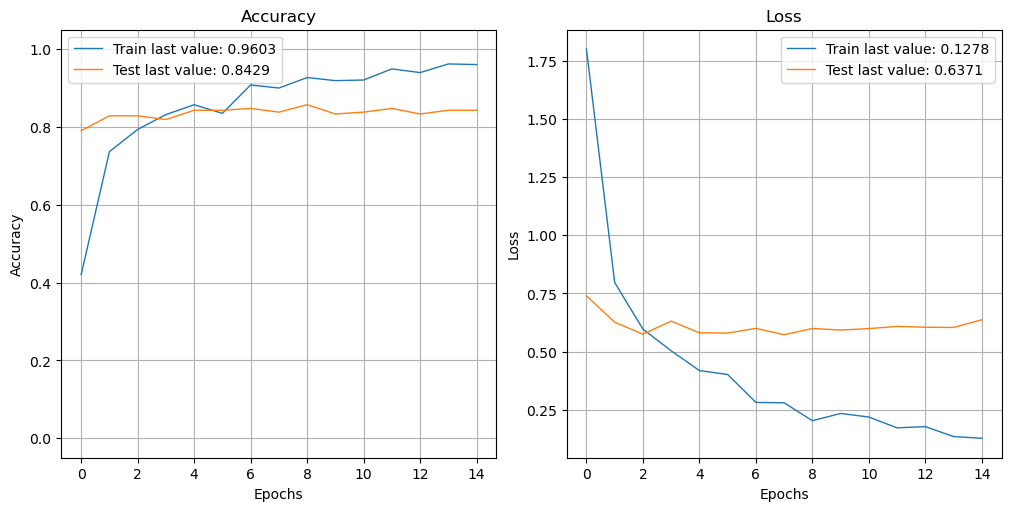

In [56]:
# Affichage de la courbe d'apprentissage de l'accuracy et de la fonction cout
show_history(history5)
plot_history(history5, path="../Output/Courbe_d'apprentissage/Courbe_d'apprentissage_MobileNet.png")
plt.close()

L’analyse des courbes d’apprentissage révèle que le modèle peine à améliorer ses performances sur les données de validation au fil des epochs. En effet, bien que l’accuracy mesurée sur ces données soit correcte dès le départ, elle reste relativement stable au cours des 12 epochs, tout comme la fonction de coût, qui ne montre pas de diminution significative. Ce plateau dans les performances suggère que le modèle n’arrive pas à mieux généraliser sur des données non vues, malgré l’entraînement.

En revanche, comme cela a déjà été observé avec le modèle VGG16, une amélioration rapide au début est clairement visible sur les données d'entraînement. L'accuracy augmente rapidement lors des premiers epochs, tout comme la fonction de coût, indiquant que le modèle apprend efficacement à mieux prédire les catégories du jeu d'entraînement. Malgrès l'ajout de data augmentation, on note l'existence d'un léger surapprentissage du modèle.

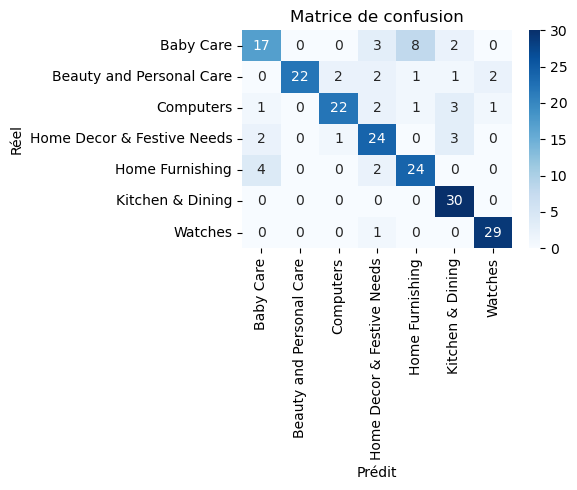

                            precision    recall  f1-score   support

                 Baby Care       0.71      0.57      0.63        30
  Beauty and Personal Care       1.00      0.73      0.85        30
                 Computers       0.88      0.73      0.80        30
Home Decor & Festive Needs       0.71      0.80      0.75        30
           Home Furnishing       0.71      0.80      0.75        30
          Kitchen & Dining       0.77      1.00      0.87        30
                   Watches       0.91      0.97      0.94        30

                  accuracy                           0.80       210
                 macro avg       0.81      0.80      0.80       210
              weighted avg       0.81      0.80      0.80       210



In [57]:
# Prédictions des probas de chaque classes pour chaque images
y_test_pred_proba = model5.predict(dataset_test, verbose=0)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred_proba, axis=1) 

# Définition les labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test_true, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test_true, y_test_pred, labels=labels)

# Décodage des catégorie
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_MobileNet.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test_true, y_test_pred, target_names=labels))

La matrice de confusion ainsi que le rapport de classification indiquent que le modèle a obtenu de bonnes performances globales, avec une accuracy de 80 % sur les données de test.

Cependant, les résultats varient selon les catégories. On observe une précision parfaite pour la catégorie Beauty and Personal Care, ce qui signifie que tous les produits prédits comme appartenant à cette catégorie le sont effectivement. De même, la catégorie Kitchen and Dining se distingue par un rappel parfait, indiquant que tous les produits de cette catégories ont été correctement identifiés par le modèle. Pour les autres catégories, les précisions varient entre 71 % et 91 %, tandis que les rappels fluctuent entre 57 % et 97 %, ce qui traduit une hétérogénéité dans la capacité du modèle à bien classifier les produits de certaines catégories.

La performance la plus faible en rappel est observée pour la catégorie Baby Care, avec un score de 57 %. Cela signifie qu’une part importante des produits de cette catégorie n’a pas été correctement identifiée. La matrice de confusion montre que ces produits ont été principalement prédits à tort comme appartenant à la catégorie Home Furnishing, suggérant une certaine similarité perçue par le modèle entre ces deux catégorie.

In [58]:
# Création de la dataframe de résultats associés au modèle 3
Resultats_5 = pd.DataFrame({
    'approche': ['model5'],
    'accuracy_train': [accuracy_train_5],
    'accuracy_val': [accuracy_val_5],
    'accuracy_test': [ accuracy_test_5],
    "temps d'entraînement": [duration_5]
})

# Ajout des résulats du modèle 2 dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_5])

# Affichage de la dataframe de résultats
Resultats

# Sauvegarde de la dataframe de Résultats
Resultats.to_csv('../Output/Table/Comparaison_approches.csv')

## Comparaison des performances du modèle MobileNet avec VGG16

C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:615: PlotnineWarning: Saving 12 x 8 in image.
C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:616: PlotnineWarning: Filename: ../Output/Comparaison_modèles/Comparaison_modèles


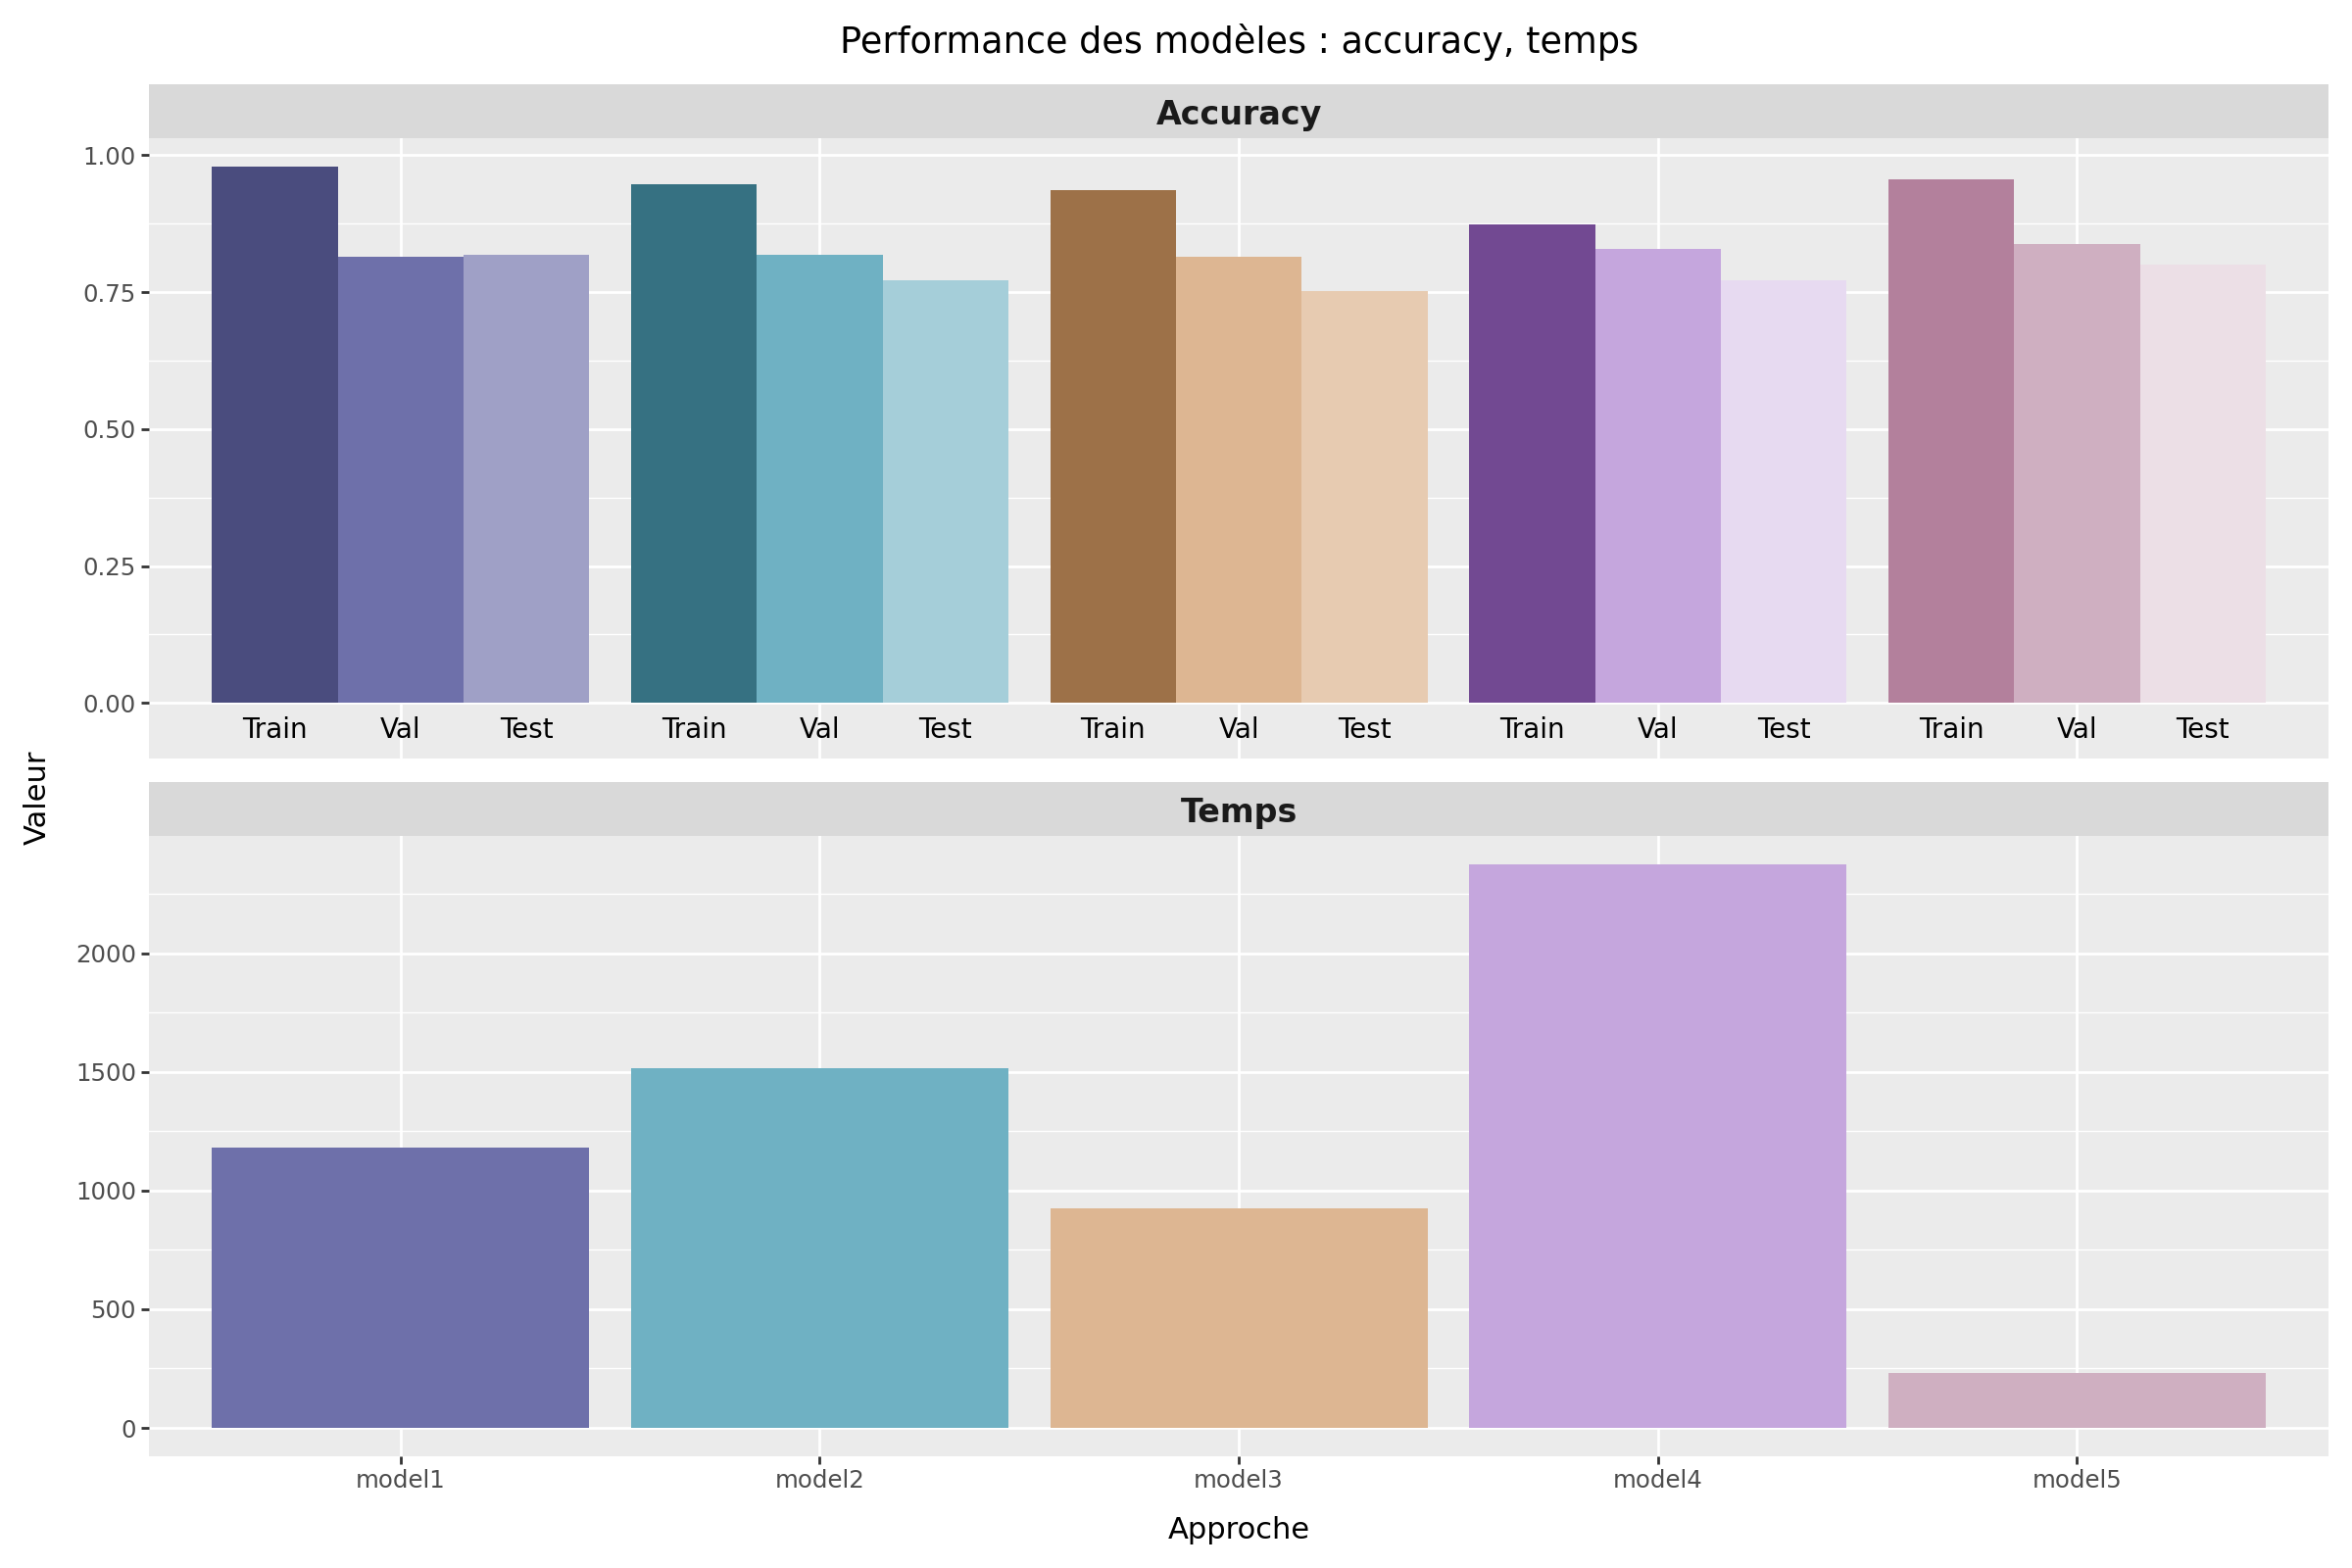

In [59]:
# Définition d'un dictionnaire de correspondance de couleur
custom_colors = {
    # Accuracy 
    'Train_model1': '#4a4c7e','Validation_model1': '#6e70aa','Test_model1': '#9fa0c6',  
    'Train_model2': '#367182','Validation_model2': '#6fb1c3','Test_model2': '#a5ced9',
    'Train_model3': '#9d7148','Validation_model3': '#ddb692','Test_model3': '#e7cbb1',
    'Train_model4': '#724992','Validation_model4': '#c5a6dd','Test_model4': '#e7daf1',
    'Train_model5': '#b3809c','Validation_model5': '#cfafc1','Test_model5': '#ecdfe6',

    # Temps d'entraînement 
    "Temps d'entraînement_model1": '#6e70aa',
    "Temps d'entraînement_model2": '#6fb1c3',
    "Temps d'entraînement_model3": '#ddb692',
    "Temps d'entraînement_model4": '#c5a6dd',
    "Temps d'entraînement_model5": '#cfafc1',

}

# Détermination de l'ordre d'apparition des bar dans le barplot
ordre = [
    'Train_model1', 'Validation_model1', 'Test_model1',
    'Train_model2', 'Validation_model2', 'Test_model2',
    'Train_model3', 'Validation_model3', 'Test_model3',
    'Train_model4', 'Validation_model4', 'Test_model4',
    'Train_model5', 'Validation_model5', 'Test_model5',

    "Temps d'entraînement_model1", "Temps d'entraînement_model2",
    "Temps d'entraînement_model3", "Temps d'entraînement_model4",
    "Temps d'entraînement_model5"    
]

# Appel de la fonction
plot_resultats_modeles(df_resultats=Resultats, ordre_score_approche= ordre, dict_couleurs=custom_colors, save_name="Comparaison_modèles")

L’utilisation du modèle MobileNet, en suivant la même approche que celle utilisée pour le modèle 4, a permis d’obtenir des performances similaires à celles de VGG16, tout en réduisant significativement le temps de calcul.
Il serait intéressant d'optmiser ce modèle en ajustant certains hyperparamètres, comme la taille des batch, le nombre de neurones dans la couche dense entrainable, le taux d'apprentissage ou encore le pourcentage de neurones à supprimer lors de la phase de dropout, afin de voir s'il est possible d'améliorer ses performances et de réduire le surapprentissage observé avec ce modèle.

## Optimisation

In [60]:
# Initialisation des résultats
results = []

# Initialisation de la liste des callbacks 
callbacks_list = [] 

# Définition du numéro du premier modèle
i=6

# Pour chaque combinaison de d'hyperparamètres
for batch_size in [16, 32]:
    for learning_rate in [0.0001, 0.001, 0.01]:
        for dropout in [0.3, 0.5]:
            for dense_size in [128, 256, 512]:
                
                # Affichage des hyperparamètres testés
                print(f'test of batch_size: {batch_size}, lr: {learning_rate}, dropout:{dropout}, ds:{dense_size}')

                # Création du modèle à chaque itération
                with tf.device('/gpu:0'):
                    model5_opt = create_model_fct3(learning_rate=learning_rate,
                                                   dropout=dropout,
                                                   dense_size=dense_size,
                                                   show_model=False)

                # Définition du nom de fichier de sauvegarde selon les paramètres testés
                model5_opt_save_path = f"../Models/CNN/Optimisation/MobileNet_best_weights_bs{batch_size}_lr{learning_rate}_do{dropout}_ds{dense_size}.keras"
        
                # Définition du checkpoint 
                checkpoint = ModelCheckpoint(
                    model5_opt_save_path,
                    monitor='val_loss',
                    verbose=0,
                    save_best_only=True,
                    mode='min'
                )
                # Défintion des callback
                es = EarlyStopping(monitor='val_loss', mode='min', verbose=0, patience=7)
                callbacks = [checkpoint, es]

                # Entraînement du modèle
                start = time.time()
                history = model5_opt.fit(
                    dataset_train,
                    validation_data=dataset_val,
                    batch_size=batch_size,
                    epochs=50,
                    callbacks=callbacks,
                    verbose=0)

                # Calcul du temps d'entrainement 
                duration = time.time() - start

                # Chargement des meilleurs poids avant évaluation
                model5_opt.load_weights(model5_opt_save_path)

                # Evaluation des performances avec les poids enregistrés
                train_loss, train_acc = model5_opt.evaluate(dataset_train, verbose=0)
                val_loss, val_acc = model5_opt.evaluate(dataset_val, verbose=0)
                test_loss, test_acc = model5_opt.evaluate(dataset_test, verbose=0)

                # Stockage dans la liste de résultats
                results.append({
                    'approche': f'model{i}', 
                    'batch_size': batch_size,
                    'learning_rate': learning_rate,
                    'dense_size': dense_size,
                    'dropout': dropout,
                    'accuracy_train': train_acc, 
                    'accuracy_val': val_acc,
                    'accuracy_test': test_acc,
                    "temps d'entraînement": duration
                })
                
                # Incrémentation du numéro du modèle
                i = i + 1

# Conversion en DataFrame
Resultats_opt = pd.DataFrame(results)

# Sauvegarde de la table de résultats
Resultats_opt.to_csv("../Output/Table/Resultats_opt.csv")

test of batch_size: 16, lr: 0.0001, dropout:0.3, ds:128
test of batch_size: 16, lr: 0.0001, dropout:0.3, ds:256
test of batch_size: 16, lr: 0.0001, dropout:0.3, ds:512
test of batch_size: 16, lr: 0.0001, dropout:0.5, ds:128
test of batch_size: 16, lr: 0.0001, dropout:0.5, ds:256
test of batch_size: 16, lr: 0.0001, dropout:0.5, ds:512
test of batch_size: 16, lr: 0.001, dropout:0.3, ds:128
test of batch_size: 16, lr: 0.001, dropout:0.3, ds:256
test of batch_size: 16, lr: 0.001, dropout:0.3, ds:512
test of batch_size: 16, lr: 0.001, dropout:0.5, ds:128
test of batch_size: 16, lr: 0.001, dropout:0.5, ds:256
test of batch_size: 16, lr: 0.001, dropout:0.5, ds:512
test of batch_size: 16, lr: 0.01, dropout:0.3, ds:128
test of batch_size: 16, lr: 0.01, dropout:0.3, ds:256
test of batch_size: 16, lr: 0.01, dropout:0.3, ds:512
test of batch_size: 16, lr: 0.01, dropout:0.5, ds:128
test of batch_size: 16, lr: 0.01, dropout:0.5, ds:256
test of batch_size: 16, lr: 0.01, dropout:0.5, ds:512
test of ba

In [61]:
# Chargement de la table de résultats
Resultats_opt=pd.read_csv("../Output/Table/Resultats_opt.csv")

# Affichage des 10 combinaisons aboutissant au meilleure score d'accuracy sur les données de validation
Resultats_opt.sort_values('accuracy_val', ascending=False).head(10)

,Unnamed: 0,approche,batch_size,learning_rate,dense_size,dropout,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
1,1,model7,16,0.0001,256,0.3,0.949206,0.866667,0.800000,182.208629
8,8,model14,16,0.0010,512,0.3,0.980952,0.861905,0.790476,259.854552
28,28,model34,32,0.0010,256,0.5,0.925397,0.857143,0.823810,183.199927
20,20,model26,32,0.0001,512,0.3,0.963492,0.852381,0.761905,207.173931
17,17,model23,16,0.0100,512,0.5,0.968254,0.852381,0.800000,230.076931
13,13,model19,16,0.0100,256,0.3,0.965079,0.852381,0.814286,199.298029
22,22,model28,32,0.0001,256,0.5,0.957143,0.852381,0.785714,202.846483
10,10,model16,16,0.0010,256,0.5,0.923810,0.852381,0.804762,182.339049
31,31,model37,32,0.0100,256,0.3,0.968254,0.852381,0.814286,211.725922
3,3,model9,16,0.0001,128,0.5,0.922222,0.852381,0.809524,212.178651


In [62]:
# Affichage de la ligne correspondant au paramètres par défaut du modèle MobileNet
Resultats_opt[(Resultats_opt['batch_size']==32) & (Resultats_opt['learning_rate']==0.001) &
             (Resultats_opt['dense_size']==256) & (Resultats_opt['dropout']==0.5)]

,Unnamed: 0,approche,batch_size,learning_rate,dense_size,dropout,accuracy_train,accuracy_val,accuracy_test,temps d'entraînement
28,28,model34,32,0.001,256,0.5,0.925397,0.857143,0.82381,183.199927


C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:615: PlotnineWarning: Saving 12 x 8 in image.
C:\Users\33647\anaconda3\envs\env_p6_py311\Lib\site-packages\plotnine\ggplot.py:616: PlotnineWarning: Filename: ../Output/Comparaison_modèles/Comparaison_optimisation_MobileNet


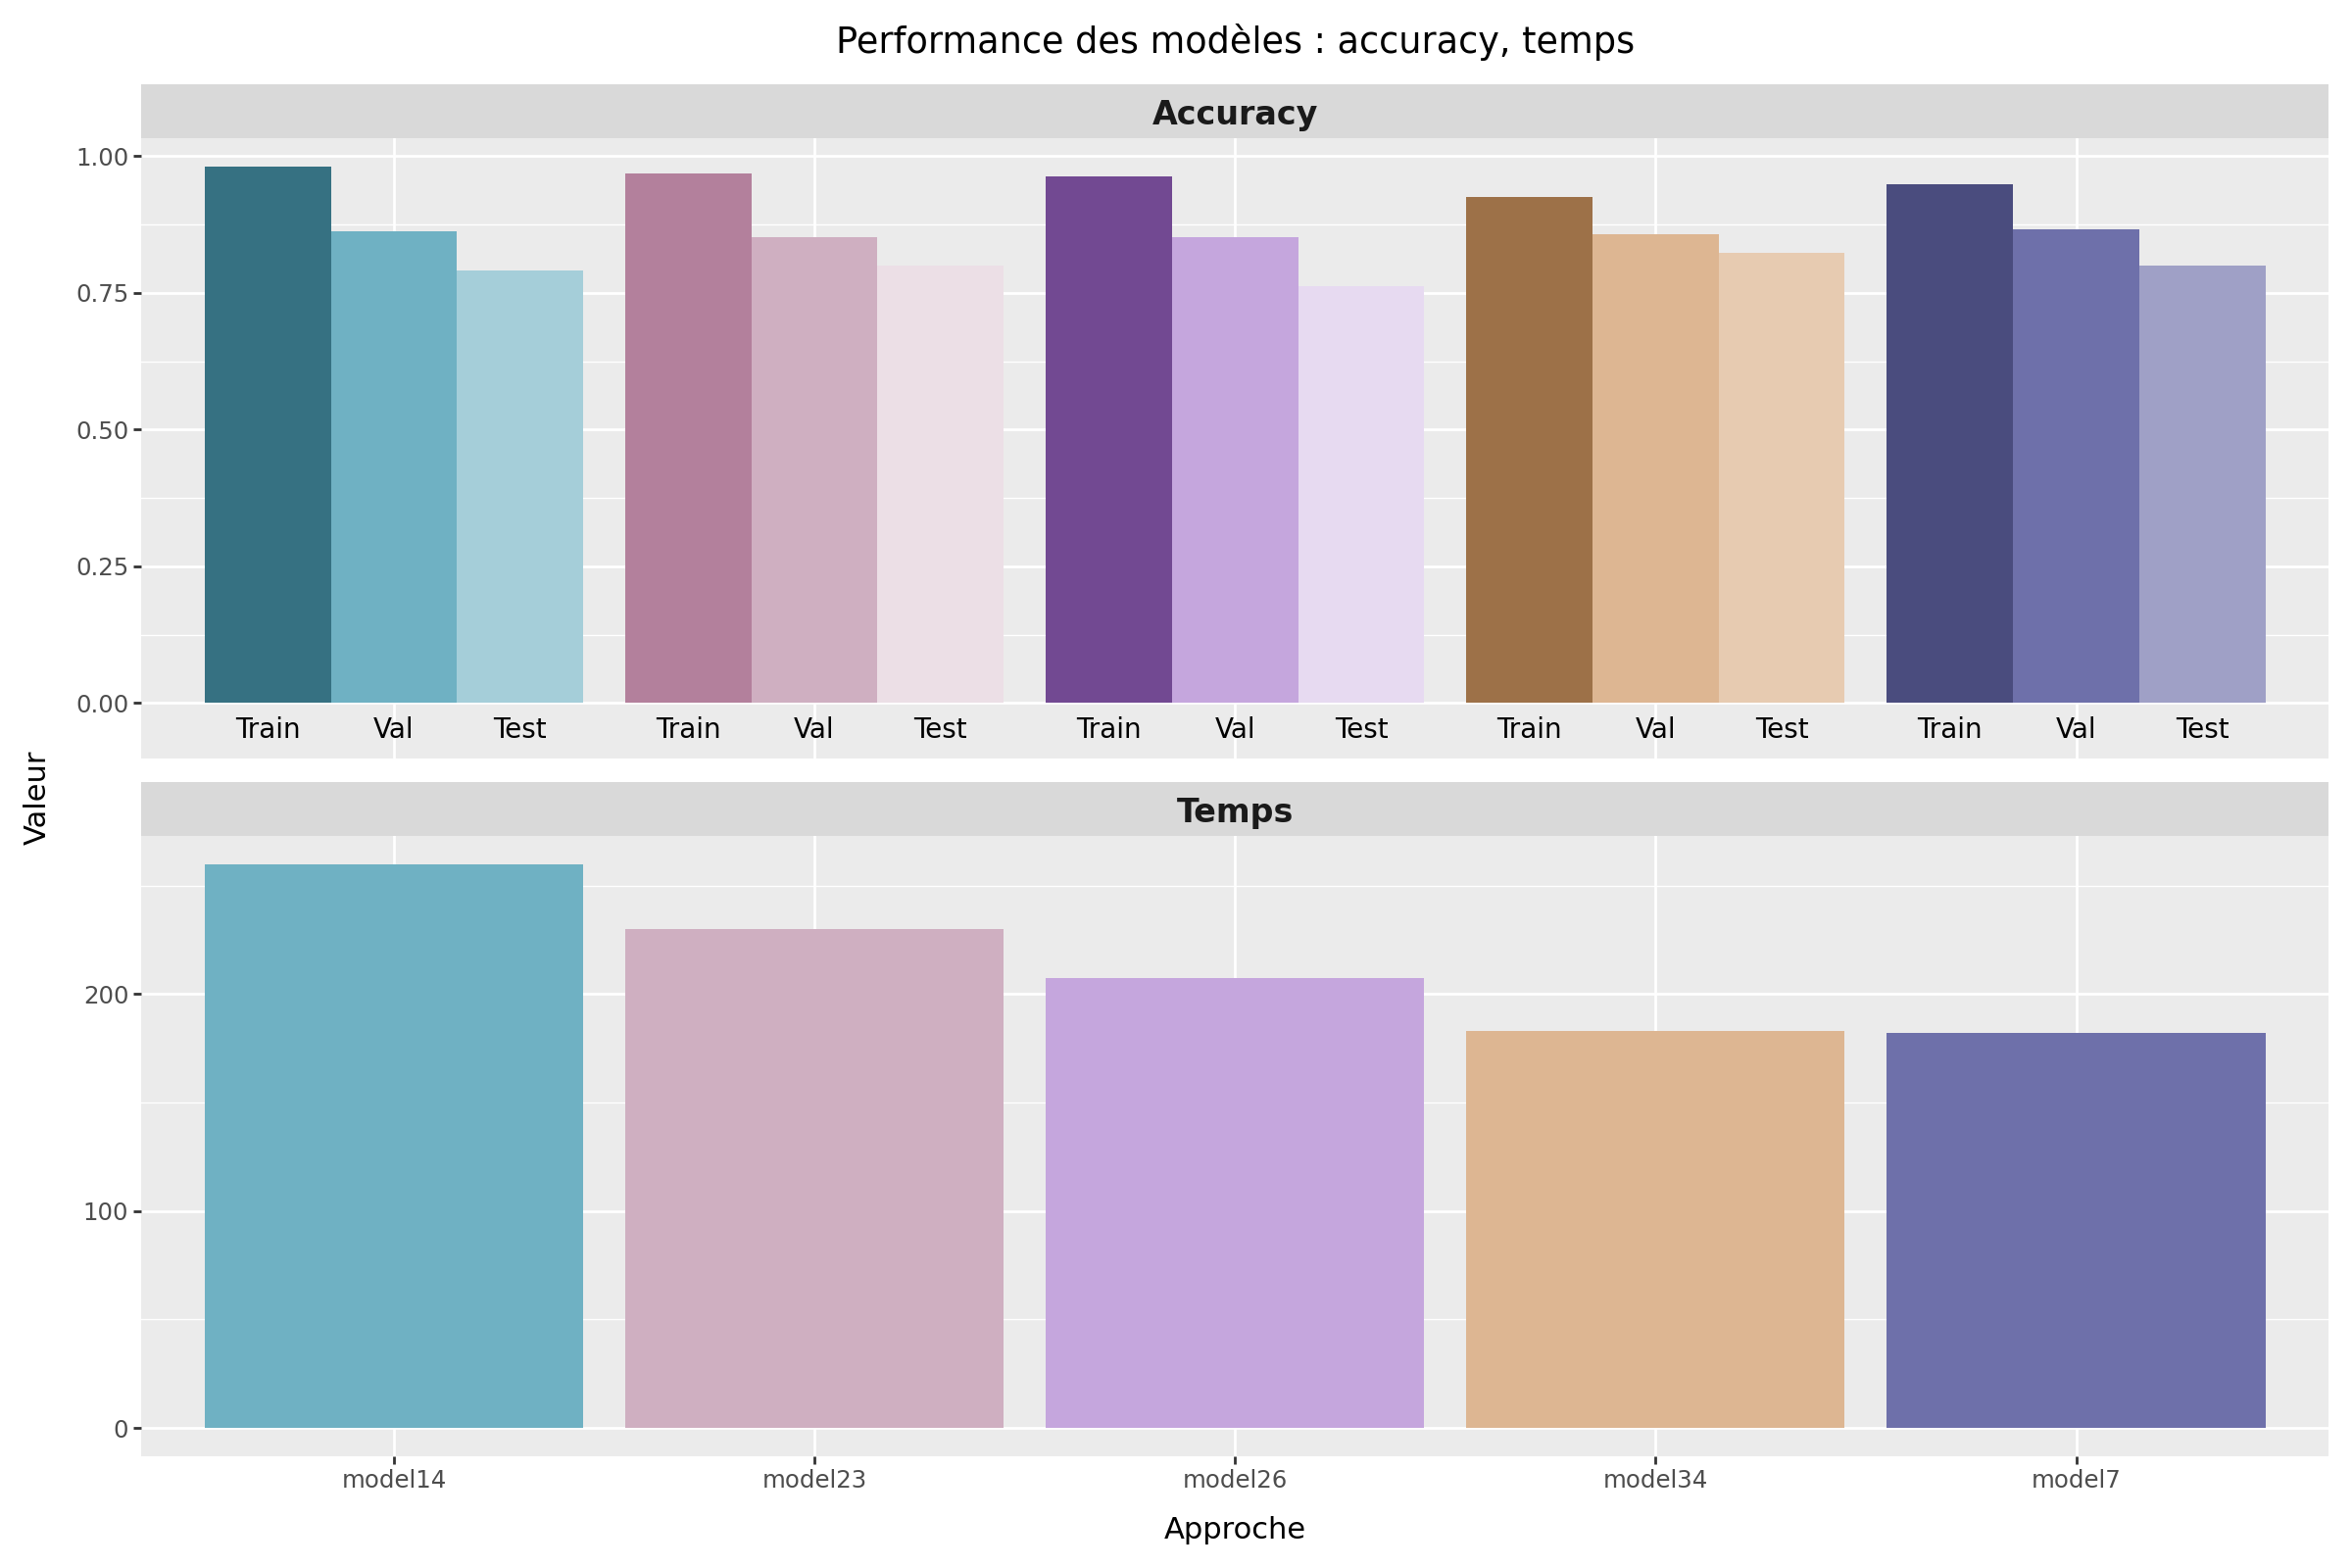

In [63]:
# Selection des 5 meilleurs modèles
Resultats_opt_best = Resultats_opt.sort_values('accuracy_val', ascending=False).head(5)

# Définition des différents type de barre
scores = ['Train', 'Validation', 'Test', "Temps d'entraînement"]

# Définition des couleurs en fonction des types d'information
couleurs_train = ['#4a4c7e', '#367182', '#9d7148', '#724992', '#b3809c']
couleurs_val = ['#6e70aa', '#6fb1c3', '#ddb692', '#c5a6dd', '#cfafc1']
couleurs_test = ['#9fa0c6', '#a5ced9', '#e7cbb1', '#e7daf1', '#ecdfe6']
couleurs_temps = ['#6e70aa', '#6fb1c3', '#ddb692', '#c5a6dd', '#cfafc1']

# Définition des modèles à afficher
modeles = ['model7', 'model14', 'model34', 'model26', 'model23']

# Construction d'un dictionnaire de couleur
custom_colors = {}
for i, modele in enumerate(modeles):
    custom_colors[f'Train_{modele}'] = couleurs_train[i]
    custom_colors[f'Validation_{modele}'] = couleurs_val[i]
    custom_colors[f'Test_{modele}'] = couleurs_test[i]
    custom_colors[f"Temps d'entraînement_{modele}"] = couleurs_temps[i]

# Définition de l'ordre d'apparition des barres
ordre = []
for modele in modeles:
    for score in scores:
        ordre.append(f"{score}_{modele}")

# Appel de la fonction
plot_resultats_modeles(df_resultats=Resultats_opt_best, ordre_score_approche= ordre, dict_couleurs=custom_colors, save_name="Comparaison_optimisation_MobileNet")

D’après le tableau, c’est le modèle 7 qui a obtenu le meilleur score d’accuracy sur les données de validation. L’analyse du graphique représentant les résultats de performances des différentes combinaisons d’hyperparamètres ayant conduit aux 5 meilleurs accuracy sur les données de validation montre que les temps de calcul sont relativement similaires, compris entre 182 et 259 secondes, et que les performances en termes d’accuracy mesuré sur les trois sous ensemble de données sont globalement proches.

Il est toutefois intéressant de noter que le modèle 7 qui correspond à celui ayant permis d’atteindre le meilleur score d’accuracy sur les données de validation est également celui qui présente le temps de calcul le plus faible, ce qui en fait un modèle particulièrement prometteur. Par ailleurs, après calcul, l’écart entre l’accuracy mesurée sur les données d’entraînement et celle mesurée sur les données de validation pour ce modèle est le deuxième plus faible, juste après celui observé pour le modèle 34 (qui correspond en réalité au même paramétrage testé à l’étape précédente avant l’optimisation). Cela suggère une bonne capacité de généralisation, avec un risque limité de surapprentissage. 

Avant de conclure on va analyser de facon détaillée la matrice de confusion et le rapport de classification de ce modèle.

## Evaluation du meilleur modèle après optimisation

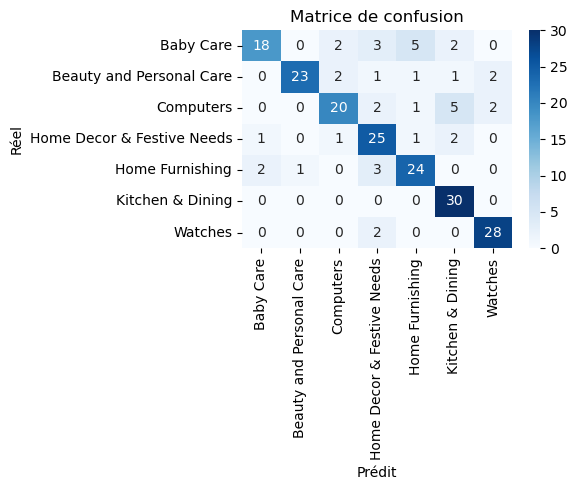

                            precision    recall  f1-score   support

                 Baby Care       0.86      0.60      0.71        30
  Beauty and Personal Care       0.96      0.77      0.85        30
                 Computers       0.80      0.67      0.73        30
Home Decor & Festive Needs       0.69      0.83      0.76        30
           Home Furnishing       0.75      0.80      0.77        30
          Kitchen & Dining       0.75      1.00      0.86        30
                   Watches       0.88      0.93      0.90        30

                  accuracy                           0.80       210
                 macro avg       0.81      0.80      0.80       210
              weighted avg       0.81      0.80      0.80       210



In [64]:
# Chargement du modèle
model7 = load_model(f"../Models/CNN/Optimisation/MobileNet_best_weights_bs16_lr0.0001_do0.3_ds256.keras")

# Prédictions des probas de chaque classes pour chaque images
y_test_pred_proba = model7.predict(dataset_test, verbose=0)

# Extraction de la classe la plus probable pour chaque image
y_test_pred = np.argmax(y_test_pred_proba, axis=1) 

# Définition les labels selon l’ordre exact des classes dans y_test
labels = sorted(np.unique(np.concatenate((y_test_true, y_test_pred))))

# Matrice de confusion avec labels explicites
conf_mat = confusion_matrix(y_test_true, y_test_pred, labels=labels)

# Décodage des catégorie
labels = encoder.inverse_transform(labels)

# Conversion en dataframe avec les bons labels
df_cm = pd.DataFrame(conf_mat, index=labels, columns=labels)

# Construction de la figure
plt.figure(figsize = (6,5))
sns.heatmap(df_cm, annot=True, cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig(f'../Output/Matrice_de_confusion/Matrice_de_confusion_MobileNet_optimisé.png', format='png')
plt.show()

# Affichage du rapport de classification
print(classification_report(y_test_true, y_test_pred, target_names=labels))

La matrice de confusion ainsi que le rapport de classification montrent que le modèle a obtenu des performances globalement satisfaisantes sur les données test, avec une accuracy de 80%. La précision et le rappel moyens du modèle sont d’environ 80 %. Ainsi, 80 % des prédictions effectuées par le modèle sont correctes, et 80 % des produits réellement présents dans chaque catégories sont bien identifiés.

Certaines catégories ressortent comme particulièrement bien prédites par le modèle. C’est le cas de la catégorie Watches, pour laquelle les prédictions sont à la fois fiables (88 % de précision) et exhaustives (93 % de rappel). De même, la catégorie Kitchen & Dining se distingue par un rappel parfait (100 %), indiquant que le modèle a correctement identifié tous les produits de cette catégorie, même si la précision de 75 % révèle quelques erreurs parmi les prédictions.
La catégorie Beauty and Personal Care bénéficie également d’une excellente précision  de 96%, ce qui montre que lorsqu’un produit est classé dans cette catégorie, il l’est presque toujours à juste titre. Toutefois, son rappel de 77% indique que le modèle passe encore à côté de certains produits appartenant à cette catégorie.

En revanche, des catégories comme Baby Care et Computers sont moins bien prédites. Pour Baby Care, le modèle est plutôt précis, mais son rappel de seulement 60 % révèle qu’il ne détecte qu’une partie des vrais produits de cette catégorie. Le même constat s’applique à la catégorie Computers, dont le rappel est relativement bas. Enfin, Home Decor & Festive Needs montre une situation inverse : le rappel est élevé associé à cette catégorie est plutot élevée, donc la majorité des vrais cas sont bien détectés, mais la précision plus faible de 69 % suggère que le modèle y place à tort des produits qui ne devraient pas y être.

## Analyse d'exemples de produits mal classés

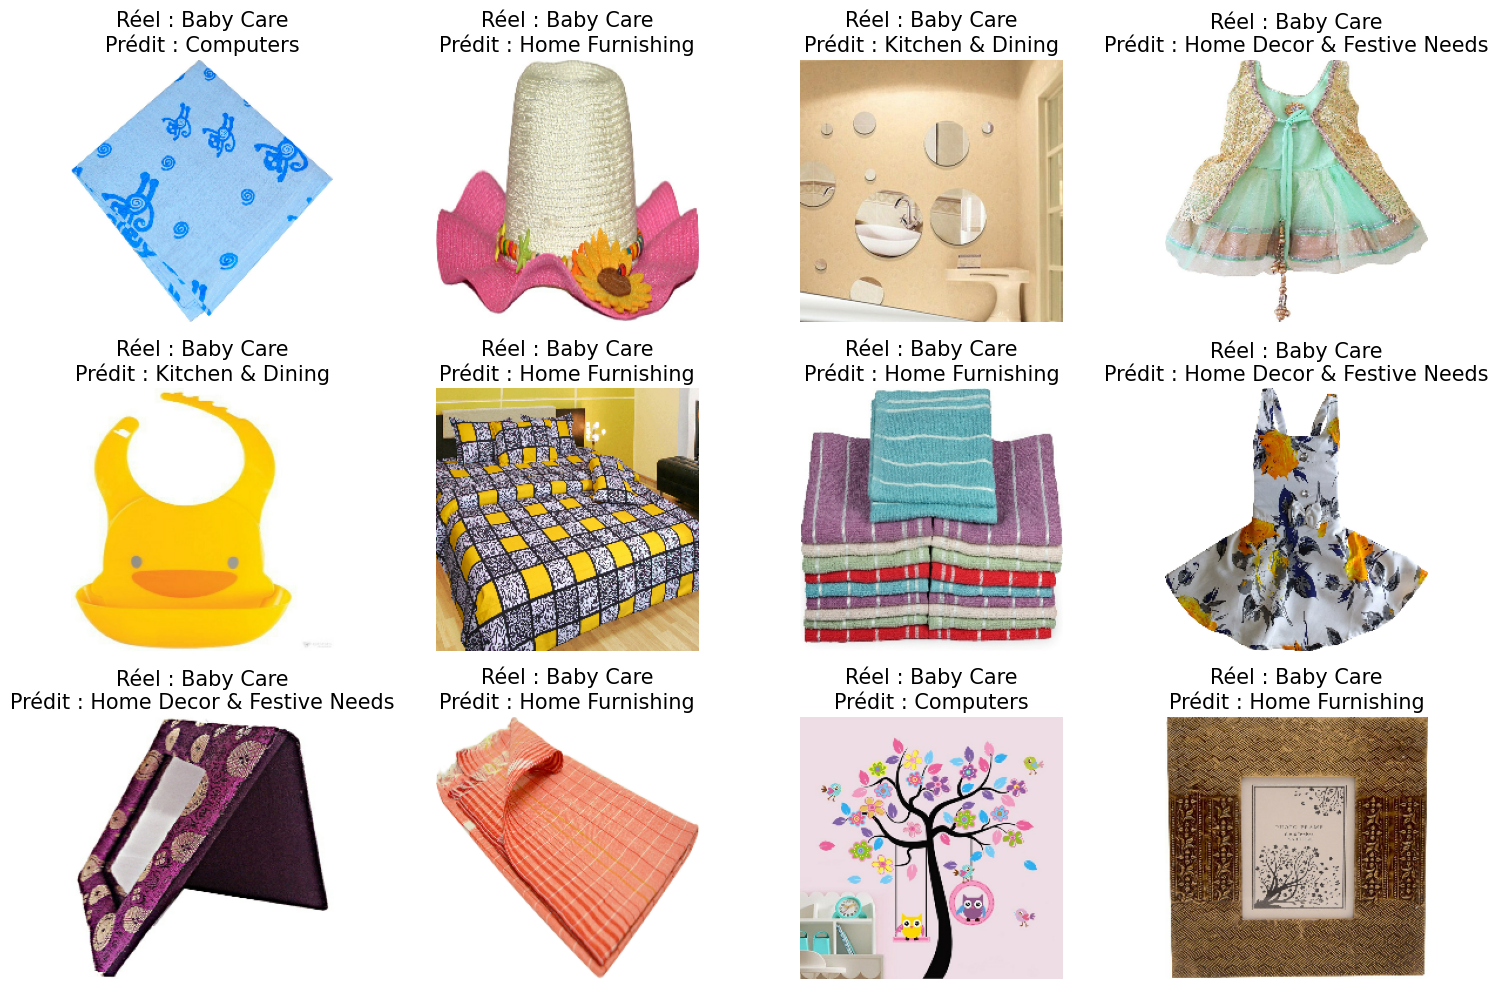

In [65]:
# Extraction des images du jeu de test
Images_test = np.concatenate([x for x, y in dataset_test], axis=0)

# Retour aux labels textuels des catégories
y_true_labels = encoder.inverse_transform(y_test_true)
y_pred_labels = encoder.inverse_transform(y_test_pred)

# Identification des indices correspondant aux mauvaises prédictions
indices_incorrects = np.where(y_test_true != y_test_pred)[0]

# Affichage de n images correspondantes
n = 12

# Initialisation de la figure
plt.figure(figsize=(15, 10))

# Pour chaque produits mal classés affichage de l'image correspondante
for i, idx in enumerate(indices_incorrects[:n]):
    plt.subplot(3, 4, i + 1)
    img = array_to_img(Images_test[idx]) 
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Réel : {y_true_labels[idx]}\nPrédit : {y_pred_labels[idx]}", fontsize=15)

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde de la figure
plt.savefig(f'../Output/Erreur_classification/Erreur_classification.png', format='png')

# Affichage de la figure
plt.show()


Les 12 premières images mal classifiées correspondent à des produits de la catégorie Baby Care. On remarque que les erreurs se répartissent vers plusieurs catégories. En particulier, comme indiqué dans la matrice de confusion:
- 2 produits ont été classés dans la catégorie Computer
- 5 produits ont été classés dans la catégorie Home furnishing
- 3 produits ont été classés dans la catégorie Home Decor & Festive needs
- 2 produits ont été classés dans la catégorie Kitchen & Dining

  
Ces erreurs de prédictions pourraient s'expliquer par différents facteurs. Tout d'abord on peut remarquer que certains produits de puériculture mal classés partagent des similitudes très importantes avec des produits d'autres catégories. C'est le cas de la serviette et de la parrure de lit qui sont des produits qu'on peut également frequemment retrouver dans la catégorie Home Furnishing. De même le sticker pour enfant ressemble à certains autocollants présents dans la catégorie Computers. Les mêmes explications peuvent être attribuées au produits prédits dans la catégorie Home Decor. Concernant le bavoir, la prédiction de la catégorie Kitchen & Dining pourrait s'expliquer par une sous représentation de ce type de produits dans la catégorie Baby Care. Le modèle n’a donc peut être pas vu  d'exemples similaires pour bien apprendre à les identifier comme appartenant à la catégorie Baby Care.

# Conclusions

Ce projet avait pour objectif de classifier automatiquement les produits de la plateforme place de marché à partir des images de ces produits. Pour cela, 4 approches basées sur des méthodes de transfer leaning ont été explorées en utilisant dans un premier temps le modèle VGG16 pré entrainé sur les images d'ImageNet. 

- Une première approche a consisté à prétraiter les images à l'avance avant de les faire passer dans le modèle. 
- La seconde approche a ajouté une étape de data augmentation pour enrichir le jeu d'entrainement et réduire le surapprentissage.
- La troisième approche a consisté à charger les images directement à partir d'un répertoir réoganisé en fonction des classes réelles des produits sans faire de data augmentation. 
- La quatrième approche a repris le principe de la troisieme approche mais en ajoutant une étape de data augmentation directement intégrée au model. 

Les quatre approches ont abouti à des performances globalement équivalentes. Toutefois, les stratégies incluant de la data augmentation ont permis de réduire le surapprentissage. Un autre modèle moins coûteux en temps de calcul a été testé en suivant la 4ieme approche et a abouti a des performance similaires tout en réduisant de manière importante le temps d'entrainement du modèle. Grâce à ce gain de temps, il a été possible d’optimiser ce modèle en ajustant quatre hyperparamètres clés (la taille des bacth, la taille de la couche dense, le taux de dropout et le learning rate) ce qui a permis d’améliorer légèrement l’accuracy sur les données de validation. Ce modèle optimisé à permis d'obtenir une précision de 81% sur les données test et un rappel de 80% ce qui traduit une bonne capacité à prédire les catégories des produits non vus pendant l'entrainement du modèle. 